# 11 — The decision system: the book a committee can choose, question, revise and evaluate

This notebook turns the corrected models into an evaluated decision process: the trade-off a committee chooses from, the questions it asks answered by the models, why each candidate is in or out, what waiting for information is worth, what revising the book two years in is worth, and which decision process does better on the same scenarios — with the AI advisor's contribution measured apart from the optimizer's, and — in section 11 — whether an AI challenger that questions the committee's proposal improves its decision. Everything here is a post-registration extension (decisions #88–#96); the registered record is in `results/registered_v7/`.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/candidate_npv.csv`, `results/scenario_settings.csv`, `data/interim/scenario_state.npz` | the forty candidates on 1 January 2025 (notebook 07) and every scenario draw (notebook 08) |
| in | `data/interim/trackA.parquet`, `data/interim/milestones.parquet` | the agreement signal's likelihoods from the queue history |
| in | `prompts/advisor_system.md`, `prompts/whatif_translate.md`, `prompts/whatif_explain.md`, `results/advisor_runs.jsonl` | the advisor with tools; every call recorded and replayable |
| out | `results/v8/base_books.csv`, `results/v8/frontier.csv`, `results/v8/policy_choice.csv` | the base books, the frontier over risk policies, which policy each committee would choose |
| out | `results/v8/whatifs.csv`, `results/v8/explanations.csv`, `results/v8/statuses.csv` | five committee questions; each candidate's opportunity cost; invest / stage / defer / monitor / reject |
| out | `results/v8/value_of_information.csv`, `results/v8/dynamic.csv`, `results/v8/process_comparison.csv`, `results/v8/value_added.csv` | information values; staged decisions; the decision processes compared |
| out | `results/v8/advisor_tools_eval.csv`, `results/v8/checks.csv` | the advisor with tools scored; checks |
| in | `prompts/challenge_read.md`, `prompts/challenge_memo.md`, `results/v9/success_criteria_v9_registered.json` | the challenger's two rounds; the registration of decision #96 (checked, never rewritten) |
| out | `results/v9/case_check.csv`, `results/v9/x1_outputs.jsonl`, `results/v9/x1_scores.csv`, `results/v9/x2_scores.csv`, `results/v9/x2_per_case.csv`, `results/v9/x3_outputs.jsonl`, `results/v9/x3_scores.csv`, `results/v9/success_criteria_v9_scored.csv` | the challenger's experiments X1–X3 and the scored criteria C25–C32 |
| out | `figures/F38_frontier.*` … `figures/F46_challenger.*` | report figures: frontier, reallocation, attractiveness, staged decisions, value added, the architecture, the advisor with tools |

*Execution order:* after notebooks 07–09. Paths are relative to the repository root.

## Setup

Two engines over the same forty candidates (`src/whatif.py`): one on the 2,000 primary scenarios, on which every book is chosen, and one on the 2,000 held-out scenarios, on which every book is scored. The held-out set redraws prices, output, costs and timing with its own seeds (audit A7). The main case is the committee grid and the contracted revenue case; the registered grid is reported beside it.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import advisor as adv, advisor_tools as at, config, decision_date, dynamic as dy, economics as ec, optimizer as opt, paths, plots, portfolio, voi, whatif as wi

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "11_decision_system"
START = time.time()
R = paths.RESULTS
V8 = R / "v8"
V8.mkdir(exist_ok=True)
registered = json.loads((R / "success_criteria_v7_registered.json").read_text(encoding="utf-8"))
LAM, LEVEL, CAP, SEED, N_BOOT = registered["lam"], registered["level"], 0.40, 2020, 2000
GRID = "committee"  # the main case; the registered grid is reported beside it
TECH_COLOR = {"Lease redevelopment": "#D55E00", "Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]}

sel = wi.Engine(2000, "primary")
held = wi.Engine(2000, "held-out")
ids = sel.ids
tech = sel.candidates["technology"].to_numpy()
sector = sel.candidates["sector"].to_numpy()
lease_mask = sector != "ERCOT power"
TECHS = list(TECH_COLOR)


def describe(x, A_h, charge, budget):
    """A book scored on the held-out scenarios: size, charge, mean, median, P(loss), CVaR, utilization, capital by technology."""
    x = np.asarray(x, int)
    total = A_h @ x
    return {"n": int(x.sum()), "leases": int(x[lease_mask].sum()), "requests": int(x[~lease_mask].sum()), "charge": float(charge @ x),
            "utilization": float(charge @ x / budget), **dy.summarize(total, LEVEL), "violations": len(opt.violations(x, charge, budget, tech, CAP)),
            **{f"charge_{t}": float(charge[tech == t] @ x[tech == t]) for t in TECHS}, "members": ";".join(np.array(ids)[x == 1])}


print(f"engines loaded: {len(ids)} candidates, {sel.prices.shape[0]:,} primary and {held.prices.shape[0]:,} held-out scenarios; {time.time() - START:.0f} s")

engines loaded: 40 candidates, 2,000 primary and 2,000 held-out scenarios; 2 s


## 0. The system in one picture

Six layers, each a module with tests; the language model sits in one of them and never produces a number the decision uses. The second diagram is the path a committee question takes.

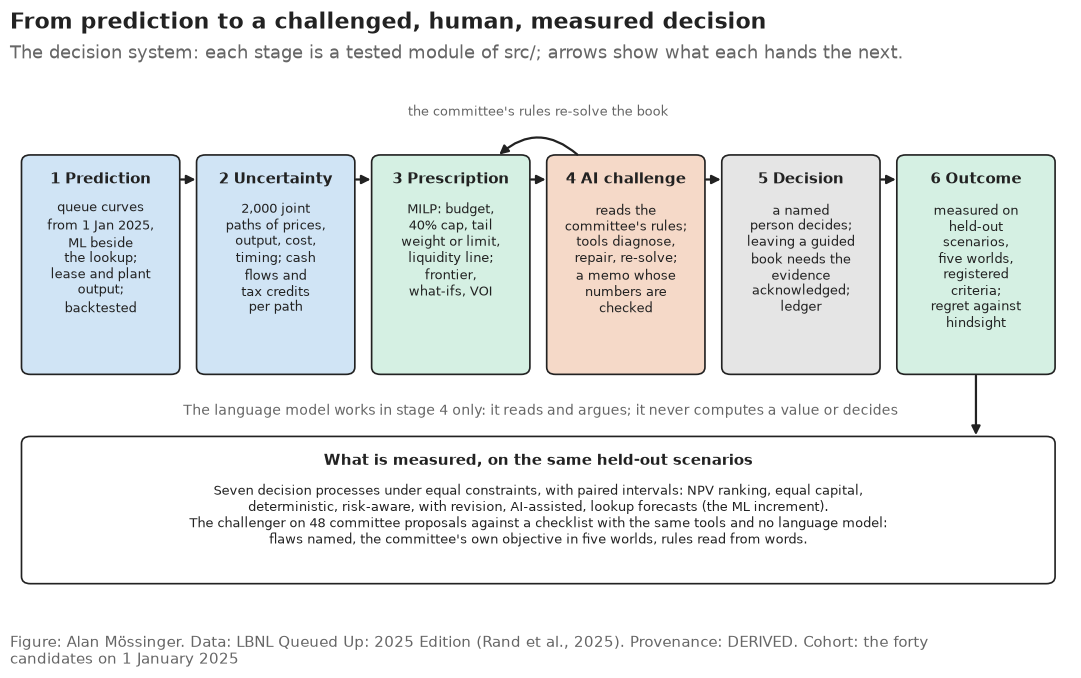

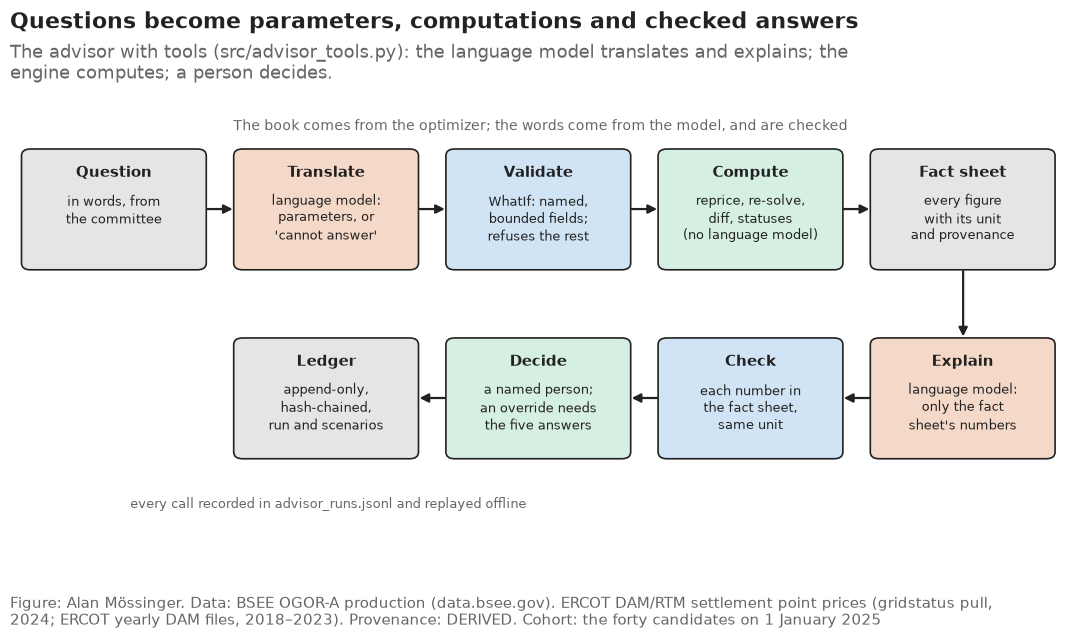

In [2]:
from matplotlib.patches import FancyBboxPatch

NL = chr(10)


def panel(ax, x, y, w, h, color, head, body, fs=10.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.1", facecolor=color, edgecolor=plots.INK, lw=1.2))
    ax.text(x + w / 2, y + h - 0.22, head, ha="center", va="top", fontsize=fs + 1.5, fontweight="bold", color=plots.INK)
    ax.text(x + w / 2, y + h - 0.62, body, ha="center", va="top", fontsize=fs, color=plots.INK, linespacing=1.3)


def arrow(ax, a, b, rad=0.0, text=None, tx=None, ty=None):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", lw=1.6, color=plots.INK, connectionstyle=f"arc3,rad={rad}"))
    if text:
        ax.text(tx, ty, text, ha="center", va="center", fontsize=9, color=plots.MUTED)


fig, ax = plt.subplots(figsize=(11, 6.8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis("off")
layers = [
    ("1 Prediction", ["queue curves", "from 1 Jan 2025,", "ML beside", "the lookup;", "lease and plant", "output;", "backtested"], "#D0E4F5"),
    ("2 Uncertainty", ["2,000 joint", "paths of prices,", "output, cost,", "timing; cash", "flows and", "tax credits", "per path"], "#D0E4F5"),
    ("3 Prescription", ["MILP: budget,", "40% cap, tail", "weight or limit,", "liquidity line;", "frontier,", "what-ifs, VOI"], "#D5F0E3"),
    ("4 AI challenge", ["reads the", "committee's rules;", "tools diagnose,", "repair, re-solve;", "a memo whose", "numbers are", "checked"], "#F5D9C8"),
    ("5 Decision", ["a named", "person decides;", "leaving a guided", "book needs the", "evidence", "acknowledged;", "ledger"], "#E5E5E5"),
    ("6 Outcome", ["measured on", "held-out", "scenarios,", "five worlds,", "registered", "criteria;", "regret against", "hindsight"], "#D5F0E3"),
]
W, H, Y = 1.75, 3.0, 3.2
xs = [0.15 + i * 1.98 for i in range(6)]
for (head, body, color), x in zip(layers, xs):
    panel(ax, x, Y, W, H, color, head, NL.join(body), fs=9)
for i in range(5):
    arrow(ax, (xs[i] + W, Y + H - 0.32), (xs[i + 1], Y + H - 0.32))  # level with the headings, clear of the text
panel(ax, 0.15, 0.3, 11.65, 2.0, "#FFFFFF", "What is measured, on the same held-out scenarios",
      NL.join(["Seven decision processes under equal constraints, with paired intervals: NPV ranking, equal capital,",
               "deterministic, risk-aware, with revision, AI-assisted, lookup forecasts (the ML increment).",
               "The challenger on 48 committee proposals against a checklist with the same tools and no language model:",
               "flaws named, the committee's own objective in five worlds, rules read from words."]), fs=9)
arrow(ax, (xs[3] + 0.35, Y + H), (xs[2] + W - 0.35, Y + H), rad=0.45, text="the committee's rules re-solve the book", tx=(xs[2] + xs[3] + W) / 2, ty=Y + H + 0.62)
arrow(ax, (xs[5] + W / 2, Y), (xs[5] + W / 2, 2.3))
ax.text(6.0, 2.62, "The language model works in stage 4 only: it reads and argues; it never computes a value or decides", ha="center", fontsize=10, color=plots.MUTED)
plots.finish(fig, "From prediction to a challenged, human, measured decision",
             "The decision system: each stage is a tested module of src/; arrows show what each hands the next.",
             "the forty candidates on 1 January 2025", lbnl=True, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="DERIVED")
plots.save_fig(fig, "F43_architecture", "The decision workflow in six stages — prediction, uncertainty, prescription, AI challenge, human decision, measured outcome — and what is measured.", NOTEBOOK)
plt.show()

fig, ax = plt.subplots(figsize=(11, 6.4))
ax.set_xlim(0, 12)
ax.set_ylim(0, 6.6)
ax.axis("off")
steps = [
    (0.15, 4.4, "Question", "in words, from" + NL + "the committee", "#E5E5E5"),
    (2.55, 4.4, "Translate", "language model:" + NL + "parameters, or" + NL + "'cannot answer'", "#F5D9C8"),
    (4.95, 4.4, "Validate", "WhatIf: named," + NL + "bounded fields;" + NL + "refuses the rest", "#D0E4F5"),
    (7.35, 4.4, "Compute", "reprice, re-solve," + NL + "diff, statuses" + NL + "(no language model)", "#D5F0E3"),
    (9.75, 4.4, "Fact sheet", "every figure" + NL + "with its unit" + NL + "and provenance", "#E5E5E5"),
    (9.75, 1.6, "Explain", "language model:" + NL + "only the fact" + NL + "sheet's numbers", "#F5D9C8"),
    (7.35, 1.6, "Check", "each number in" + NL + "the fact sheet," + NL + "same unit", "#D0E4F5"),
    (4.95, 1.6, "Decide", "a named person;" + NL + "an override needs" + NL + "the five answers", "#D5F0E3"),
    (2.55, 1.6, "Ledger", "append-only," + NL + "hash-chained," + NL + "run and scenarios", "#E5E5E5"),
]
for x, y, head, body, color in steps:
    panel(ax, x, y, 2.05, 1.75, color, head, body, fs=9.5)
for (x0, y0, *_), (x1, y1, *_) in zip(steps[:4], steps[1:5]):
    arrow(ax, (x0 + 2.05, y0 + 0.88), (x1, y1 + 0.88))
arrow(ax, (10.78, 4.4), (10.78, 3.35))
for (x0, y0, *_), (x1, y1, *_) in zip(steps[5:8], steps[6:9]):
    arrow(ax, (x0, y0 + 0.88), (x1 + 2.05, y1 + 0.88))
ax.text(3.6, 0.85, "every call recorded in advisor_runs.jsonl and replayed offline", ha="center", fontsize=9, color=plots.MUTED)
ax.text(6.0, 6.45, "The book comes from the optimizer; the words come from the model, and are checked", ha="center", fontsize=10, color=plots.MUTED)
plots.finish(fig, "Questions become parameters, computations and checked answers",
             "The advisor with tools (src/advisor_tools.py): the language model translates and explains; the engine computes; a person decides.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="DERIVED")
plots.save_fig(fig, "F44_advisor_tools", "The path of a committee question through the advisor with tools, the engine, the check, the decision and the ledger.", NOTEBOOK)
plt.show()

**Reading this.** The architecture separates the three kinds of performance the evaluation measures: forecasting (layer 2, scored by backtests and against the lookup), optimization (layer 4, scored on held-out scenarios against the conventional books) and decision support (layers 5–6, scored on translation, grounding and refusals, with the book left to the optimizer and the decision to a person). The second picture is the only route by which a language model touches the numbers, and it never writes one: it chooses parameters a validator accepts or rejects, and it explains a fact sheet that a checker holds it to.

## 1. The base books

For each grid, the risk-aware MILP (λ = 1, the registered setting) under the two-stage budget: each candidate costs the budget its stage-one charge — a lease's capital, a request's deposits plus its construction reserve (decision #90) — and the budget is the registered rule in those units, 40% of the forty charges (decision #92); no technology above 40% of the budget. Chosen on the primary scenarios, scored on the held-out ones.

In [3]:
base = {}
rows = []
for grid in ("committee", "registered"):
    b = sel.base_case(grid, "contracted")
    A_h, _ = held.matrix(wi.WhatIf(grid=grid))
    base[grid] = {**b, "A_h": A_h}
    rows.append({"grid": grid, "budget": b["budget"], **describe(b["x"], A_h, b["charge"], b["budget"])})
base_books = pd.DataFrame(rows)
base_books.to_csv(V8 / "base_books.csv", index=False)
b = base[GRID]
A, A_h, charge, budget, x_D = b["A"], b["A_h"], b["charge"], b["budget"], b["x"]
print(f"{time.time() - START:.0f} s")
base_books.drop(columns="members").assign(**{c: base_books[c] / 1e9 for c in ("budget", "charge", "mean", "median", "cvar_loss") + tuple(f"charge_{t}" for t in TECHS)}).round(3)

68 s


,grid,budget,n,leases,requests,charge,utilization,mean,median,p_loss,cvar_loss,violations,charge_Lease redevelopment,charge_Gas CC,charge_Solar,charge_Wind,charge_Storage
0,committee,3.417,13,6,7,3.299,0.965,2.052,1.533,0.104,1.019,0,1.231,0.699,0.563,0.806,0.000
1,registered,1.911,21,14,7,1.848,0.967,7.671,7.102,0.000,-2.199,0,0.760,0.298,0.000,0.764,0.027


**Reading this.** Under the committee grid the risk-aware book spends 96.5% of the $3.42 billion budget on six leases and seven requests — five wind, one solar, one gas — expects $2.05 billion (median $1.53 billion) and loses money in 10.4% of held-out scenarios, with a worst-5% average loss of $1.02 billion. Under the registered grid, where a lease is cheap against the barrels it buys, the same rule holds fourteen leases and seven requests, expects $7.67 billion and almost never loses money. The two grids give different books, which is why both are shown: the committee grid is the one an investment committee would use, the registered grid the one fixed before any result. For a lender, the committee-grid book is a portfolio with a one-in-ten chance of losing money, not a safe one. Every candidate is valued on what was public on 1 January 2025 (decision #94).

## 2. The trade-off a committee chooses from

The four books of the registration — **A** NPV ranking, **B** equal capital by sector, **C** the deterministic MILP, **D** the risk-aware MILP — are now held to the same budget and cap (audit A1). Beside them, the frontier: the MILP at nine values of λ and at hard limits on the worst-5% loss. Each committee weighs expected NPV against the tail differently; for a committee that maximizes E[NPV] − w × CVaR95, the last table says which policy it picks for each weight w. The framework does not choose w; it shows what each w buys. As a sensitivity, the four books are also solved at a budget of 40% of the candidates' full capital (decision #92), where nothing binds.

In [4]:
mu = A.mean(axis=0)
books = {"A NPV ranking": opt.top_n_by_npv(mu, charge, budget, groups=tech, group_cap=CAP),
         "B equal capital by sector": opt.equal_capital_by_sector(mu, charge, sector, budget, groups=tech, group_cap=CAP),
         "C deterministic MILP": opt.solve_milp(A, charge, budget, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP)["x"],
         "D risk-aware MILP": x_D}
front = []
for lam in (0, 0.25, 0.5, 1, 2, 4, 8, 16, 32):
    x = opt.solve_milp(A, charge, budget, lam=lam, level=LEVEL, groups=tech, group_cap=CAP)["x"]
    front.append({"policy": f"lambda {lam:g}", "kind": "penalty", "setting": lam, **describe(x, A_h, charge, budget)})
cvar_D = opt.cvar(-(A @ x_D), LEVEL)
for share in (0.75, 0.5, 0.25, 0.1):
    limit = cvar_D * share if cvar_D > 0 else cvar_D - abs(cvar_D) * (1 - share)
    try:
        x = opt.solve_milp(A, charge, budget, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP, cvar_cap=limit)["x"]
        front.append({"policy": f"CVaR limit {share:.0%} of D", "kind": "limit", "setting": limit, **describe(x, A_h, charge, budget)})
    except opt.InfeasibleBook:
        front.append({"policy": f"CVaR limit {share:.0%} of D", "kind": "limit", "setting": limit, "n": 0, "members": "no feasible book"})
for name, x in books.items():
    front.append({"policy": name, "kind": "comparator", "setting": np.nan, **describe(x, A_h, charge, budget)})
# sensitivity (decision #92): the budget at 40% of full capital instead of 40% of stage-one charges
budget_capital = 0.40 * sel.capital(wi.WhatIf(grid=GRID)).sum()
for name, x in {"A NPV ranking": opt.top_n_by_npv(mu, charge, budget_capital, groups=tech, group_cap=CAP),
                "B equal capital by sector": opt.equal_capital_by_sector(mu, charge, sector, budget_capital, groups=tech, group_cap=CAP),
                "C deterministic MILP": opt.solve_milp(A, charge, budget_capital, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP)["x"],
                "D risk-aware MILP": opt.solve_milp(A, charge, budget_capital, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"]}.items():
    front.append({"policy": f"{name}, budget 40% of capital", "kind": "sensitivity", "setting": budget_capital, **describe(x, A_h, charge, budget_capital)})
frontier = pd.DataFrame(front)
frontier.to_csv(V8 / "frontier.csv", index=False)
feasible = frontier[frontier["kind"].isin(["penalty", "limit"])].dropna(subset=["mean"]).drop_duplicates(subset=["members"])
choice = []
for w in np.round(np.arange(0, 10.01, 0.25), 2):
    utility = feasible["mean"] - w * feasible["cvar_loss"]
    best = feasible.loc[utility.idxmax()]
    choice.append({"tail_weight_w": w, "policy": best["policy"], "mean": best["mean"], "cvar_loss": best["cvar_loss"], "members": best["members"]})
policy_choice = pd.DataFrame(choice)
policy_choice.to_csv(V8 / "policy_choice.csv", index=False)
switches = policy_choice[policy_choice["policy"] != policy_choice["policy"].shift()]
print(f"{len(feasible)} distinct frontier books; the choice changes at w = {switches['tail_weight_w'].tolist()}; {time.time() - START:.0f} s")
frontier.drop(columns="members").assign(**{c: frontier[c] / 1e9 for c in ("charge", "mean", "median", "cvar_loss")}).round(3)

12 distinct frontier books; the choice changes at w = [0.0, 0.25, 0.75, 1.25, 2.25, 9.0]; 156 s


,policy,kind,setting,n,leases,requests,charge,utilization,mean,median,p_loss,cvar_loss,violations,charge_Lease redevelopment,charge_Gas CC,charge_Solar,charge_Wind,charge_Storage
0,lambda 0,penalty,0.000000e+00,17,5,12,3.416,1.000,2.357,1.656,0.128,1.600,0,1.350206e+09,1.182132e+09,0.000000e+00,8.060803e+08,7.793223e+07
1,lambda 0.25,penalty,2.500000e-01,16,5,11,3.365,0.985,2.355,1.660,0.126,1.575,0,1.349295e+09,1.182132e+09,0.000000e+00,8.060803e+08,2.705319e+07
2,lambda 0.5,penalty,5.000000e-01,15,5,10,3.414,0.999,2.238,1.617,0.117,1.358,0,1.319158e+09,9.962381e+08,2.656880e+08,8.060803e+08,2.705319e+07
3,lambda 1,penalty,1.000000e+00,13,6,7,3.299,0.965,2.052,1.533,0.104,1.019,0,1.230781e+09,6.986893e+08,5.631984e+08,8.060803e+08,0.000000e+00
4,lambda 2,penalty,2.000000e+00,14,5,9,3.065,0.897,1.549,1.339,0.078,0.524,0,1.091679e+09,0.000000e+00,1.167128e+09,8.060803e+08,0.000000e+00
5,lambda 4,penalty,4.000000e+00,5,0,5,0.806,0.236,0.585,-0.005,0.588,0.063,0,0.000000e+00,0.000000e+00,0.000000e+00,8.060803e+08,0.000000e+00
6,lambda 8,penalty,8.000000e+00,5,0,5,0.806,0.236,0.585,-0.005,0.588,0.063,0,0.000000e+00,0.000000e+00,0.000000e+00,8.060803e+08,0.000000e+00
7,lambda 16,penalty,1.600000e+01,3,0,3,0.665,0.194,0.489,-0.002,0.619,0.060,0,0.000000e+00,0.000000e+00,0.000000e+00,6.645291e+08,0.000000e+00
8,lambda 32,penalty,3.200000e+01,1,0,1,0.043,0.012,0.028,-0.001,0.973,0.001,0,0.000000e+00,0.000000e+00,0.000000e+00,4.250526e+07,0.000000e+00
9,CVaR limit 75% of D,limit,6.824330e+08,18,6,12,3.381,0.990,1.815,1.490,0.092,0.810,0,1.230781e+09,2.975488e+08,1.020024e+09,8.060803e+08,2.705319e+07


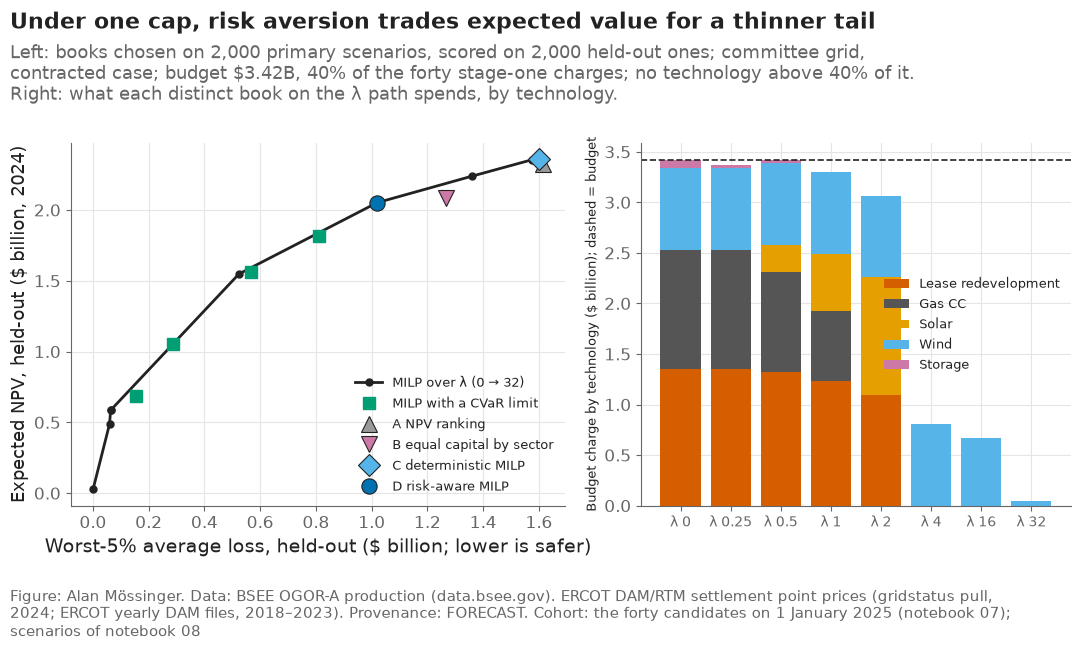

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
f = frontier[frontier["kind"] == "penalty"].sort_values("setting")
axes[0].plot(f["cvar_loss"] / 1e9, f["mean"] / 1e9, "-o", color=plots.INK, lw=2, ms=5, label="MILP over λ (0 → 32)")
lim = frontier[(frontier["kind"] == "limit") & frontier["mean"].notna()]
axes[0].plot(lim["cvar_loss"] / 1e9, lim["mean"] / 1e9, "s", color="#009E73", ms=8, label="MILP with a CVaR limit")
marks = {"A NPV ranking": ("#999999", "^"), "B equal capital by sector": ("#CC79A7", "v"), "C deterministic MILP": ("#56B4E9", "D"), "D risk-aware MILP": ("#0072B2", "o")}
for name, (col, m) in marks.items():
    r = frontier[(frontier["policy"] == name)].iloc[0]
    axes[0].plot(r["cvar_loss"] / 1e9, r["mean"] / 1e9, m, color=col, ms=11, mec=plots.INK, mew=0.8, label=name, zorder=3)
axes[0].set_xlabel("Worst-5% average loss, held-out ($ billion; lower is safer)")
axes[0].set_ylabel("Expected NPV, held-out ($ billion, 2024)")
axes[0].legend(loc="lower right", fontsize=9.5)
show = f.drop_duplicates(subset=["members"])
bottom = np.zeros(len(show))
for t in TECHS:
    vals = show[f"charge_{t}"].to_numpy() / 1e9
    axes[1].bar(np.arange(len(show)), vals, bottom=bottom, color=TECH_COLOR[t], label=t)
    bottom += vals
axes[1].set_xticks(np.arange(len(show)), [p.replace("lambda ", "λ ") for p in show["policy"]], fontsize=10)
axes[1].axhline(budget / 1e9, color=plots.INK, ls="--", lw=1.2)
axes[1].set_ylabel("Budget charge by technology ($ billion); dashed = budget")
axes[1].legend(loc="center right", fontsize=9)
plots.finish(fig, "Under one cap, risk aversion trades expected value for a thinner tail",
             f"Left: books chosen on 2,000 primary scenarios, scored on 2,000 held-out ones; committee grid, contracted case; budget ${budget / 1e9:.2f}B, 40% of the forty stage-one charges; no technology above 40% of it. "
             "Right: what each distinct book on the λ path spends, by technology.",
             "the forty candidates on 1 January 2025 (notebook 07); scenarios of notebook 08", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F38_frontier", "The efficient frontier over risk policies, the four registered books on it, and capital by technology along it.", NOTEBOOK)
plt.show()

**Reading this.** Along the λ path, expected value and tail fall together: $2.36 billion with a $1.60 billion worst-5% loss at λ = 0, $2.05 billion and $1.02 billion at λ = 1, $1.55 billion and $0.52 billion at λ = 2. From λ = 4 the book holds only five wind requests, spends 24% of the budget, expects $0.59 billion and loses money in 59% of scenarios — "safe" only because it is small, which is the scale problem of a tail measured in dollars. The CVaR-limit books are the better interface for a committee: a limit at 75% of D's tail keeps 99% of the budget at work and expects $1.82 billion with a $0.81 billion tail; at 50%, $1.56 billion and $0.57 billion. Under equal constraints NPV ranking (A) and the deterministic book (C) sit at the high-return end, equal capital (B) and the risk-aware book (D) between. The policy-choice table shows which book each tail weight w picks, switching at w = 0.25, 0.75, 1.25, 2.25 and 9 — the framework does not choose w, the committee does. As a sensitivity, at a budget of 40% of full capital nothing binds and A, B and C fund the same 38 candidates (decision #92).

## 3. Five questions a committee asks, answered by the models

Each question is a `WhatIf` — validated parameters, not prose — and the engine reprices every candidate, re-solves the book on the primary scenarios and scores it on the held-out ones. The stricter downside limit is half the worst-5% loss of book D.

In [6]:
QUESTIONS = {
    "WTI at $45 a barrel for five years": wi.WhatIf(wti_level=45.0, wti_years=5),
    "ERCOT prices half as volatile": wi.WhatIf(ercot_volatility=0.5),
    "the budget cut by a fifth": wi.WhatIf(budget_multiplier=0.8),
    "offshore redevelopment capital up 30%": wi.WhatIf(lease_cost_multiplier=1.3),
    "worst-5% loss at most half of book D's": wi.WhatIf(cvar_limit_musd=0.5 * cvar_D / 1e6),
}
answers, w_rows = {}, []
for q, w in QUESTIONS.items():
    res = sel.run(w)
    A_hw, charge_w = held.matrix(w)
    row = {"question": q, "changes": json.dumps(w.changes()), "feasible": res["feasible"], "reason": res["reason"]}
    if res["feasible"]:
        x_w = res["candidates"]["in_book"].to_numpy(int)
        new = describe(x_w, A_hw, charge_w, res["budget"])
        old = describe(x_D, A_hw, charge_w, res["budget"])  # book D held under the new conditions, for comparison
        d = res["diff"]
        row.update({"entered": ";".join(d["entered"]), "left": ";".join(d["left"]), "n_entered": len(d["entered"]), "n_left": len(d["left"]),
                    "mean_new": new["mean"], "mean_book_D_held": old["mean"], "cvar_new": new["cvar_loss"], "cvar_book_D_held": old["cvar_loss"],
                    "p_loss_new": new["p_loss"], "hhi_change": d["change"]["hhi"], **{f"charge_{t}_new": new[f"charge_{t}"] for t in TECHS}})
        answers[q] = {"result": res, "x": x_w}
    w_rows.append(row)
whatifs = pd.DataFrame(w_rows)
whatifs.to_csv(V8 / "whatifs.csv", index=False)
print(f"{time.time() - START:.0f} s")
whatifs.drop(columns=["changes", "entered", "left"]).assign(**{c: whatifs[c] / 1e9 for c in whatifs.columns if c.startswith(("mean", "cvar", "charge"))}).round(3)

345 s


,question,feasible,reason,n_entered,n_left,mean_new,mean_book_D_held,cvar_new,cvar_book_D_held,p_loss_new,hhi_change,charge_Lease redevelopment_new,charge_Gas CC_new,charge_Solar_new,charge_Wind_new,charge_Storage_new
0,WTI at $45 a barrel for five years,True,None,0,8,0.585,1.421,0.063,1.394,0.588,0.727,0.000,0.0,0.000,0.806,0.0
1,ERCOT prices half as volatile,True,None,4,1,1.567,1.510,0.592,0.837,0.082,0.073,1.231,0.0,1.286,0.806,0.0
2,the budget cut by a fifth,True,None,1,2,1.520,2.052,0.485,1.019,0.078,0.067,1.092,0.0,0.829,0.806,0.0
3,offshore redevelopment capital up 30%,True,None,0,8,0.585,1.655,0.063,1.473,0.588,0.702,0.000,0.0,0.000,0.806,0.0
4,worst-5% loss at most half of book D's,True,None,4,2,1.561,2.052,0.532,1.019,0.077,0.072,1.092,0.0,1.286,0.806,0.0


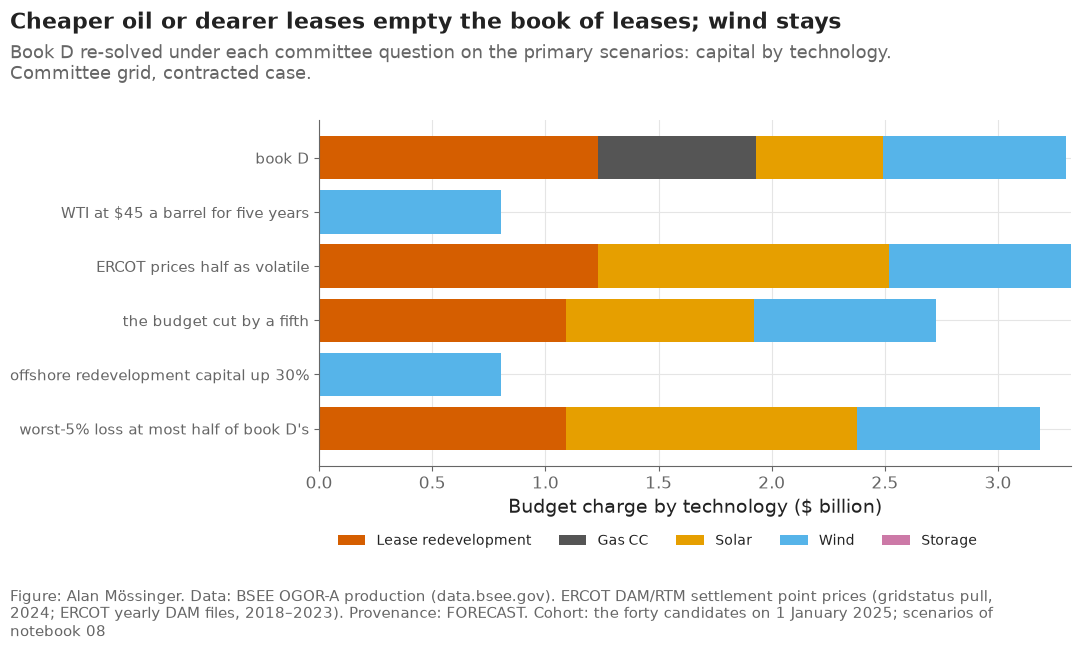

In [7]:
fig, ax = plt.subplots(figsize=(11, 6.5))
labels = ["book D"] + [q for q in QUESTIONS if q in answers]
stack = [describe(x_D, A_h, charge, budget)] + [whatifs.set_index("question").loc[q] for q in QUESTIONS if q in answers]
bottom = np.zeros(len(labels))
for t in TECHS:
    vals = np.array([s[f"charge_{t}"] if i == 0 else s[f"charge_{t}_new"] for i, s in enumerate(stack)]) / 1e9
    ax.barh(np.arange(len(labels)), vals, left=bottom, color=TECH_COLOR[t], label=t)
    bottom += vals
ax.set_yticks(np.arange(len(labels)), labels, fontsize=11)
ax.invert_yaxis()
ax.set_xlabel("Budget charge by technology ($ billion)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=5, fontsize=10, frameon=False)  # below the axis, clear of every bar
plots.finish(fig, "Cheaper oil or dearer leases empty the book of leases; wind stays",
             "Book D re-solved under each committee question on the primary scenarios: capital by technology. Committee grid, contracted case.",
             "the forty candidates on 1 January 2025; scenarios of notebook 08", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F39_reallocation", "How the book's capital moves under five committee questions.", NOTEBOOK)
plt.show()

**Reading this.** The book is most sensitive to the lease economics: oil at $45 for five years or redevelopment capital 30% higher removes all six leases, the gas request and the solar request, leaving five wind requests — a book that expects $0.59 billion and loses money in 59% of held-out scenarios but whose worst-5% loss is small, because it is small. Halving ERCOT's volatility drops the gas request and brings in four solar requests; a budget cut of a fifth drops one lease and the gas request; capping the worst-5% loss at half of book D's drops the same two and brings in the four solar requests. The gas request leaves the book in all five questions — the most fragile position in it. For a committee the first two answers matter most: the leases are the book's value, and they rest on an assumed cost and a sustained oil price.

## 4. Why each candidate is in or out

For every candidate, the book is re-solved with it forced the other way; the drop in E[NPV] − λ·CVaR is its opportunity cost (`whatif.explain`). This is a model-supported explanation: it says what the optimizer gives up on these scenarios and costs, not why a project would succeed.

In [8]:
w0 = wi.WhatIf(grid=GRID)
explanations = wi.explain(sel, w0, x_D, A, charge, budget)
status = sel.status_table(A, charge, x_D)
explanations = explanations.merge(status[["project_id", "technology", "charge_$M", "expected_npv_$M", "median_npv_$M", "p_negative", "status"]], on="project_id")
explanations["held_q05_$M"] = np.quantile(A_h, 0.05, axis=0) / 1e6
explanations["held_q95_$M"] = np.quantile(A_h, 0.95, axis=0) / 1e6
explanations.to_csv(V8 / "explanations.csv", index=False)
print(f"{time.time() - START:.0f} s")
display(explanations[explanations["in_book"]].sort_values("objective_cost_$M", ascending=False).round(1))  # every member of book D
explanations.sort_values("objective_cost_$M", ascending=False).head(15).round(1)

521 s


,project_id,in_book,objective_cost_$M,expected_npv_change_$M,cvar_change_$M,note,technology,charge_$M,expected_npv_$M,median_npv_$M,p_negative,status,held_q05_$M,held_q95_$M
23,REQ|ERCOT|26INR0113,True,548.9,-350.5,198.3,,Wind,535.3,409.7,-0.7,0.7,invest now,-0.7,1438.4
36,REQ|ERCOT|28INR0033,True,66.5,48.6,115.1,,Wind,86.7,72.7,-1.0,1.0,invest in stages,-1.0,-1.0
4,LEASE|G09982,True,54.9,-12.6,42.3,,Lease redevelopment,395.4,306.0,260.0,0.1,invest now,-100.5,906.7
37,REQ|ERCOT|28INR0113,True,51.7,-367.7,-316.1,,Wind,42.5,34.6,-0.6,1.0,invest in stages,-0.6,-0.6
30,REQ|ERCOT|27INR0061,True,45.3,57.6,102.9,,Wind,83.5,63.6,-1.3,1.0,invest in stages,-1.3,-1.3
16,LEASE|G25814,True,38.0,19.5,57.5,,Lease redevelopment,134.7,104.7,88.5,0.1,invest now,-34.0,304.6
39,REQ|ERCOT|30INR0004,True,32.0,75.2,107.2,,Wind,58.0,46.0,-0.9,1.0,invest in stages,-0.9,-0.9
15,LEASE|G16783,True,25.5,32.8,58.4,,Lease redevelopment,121.9,91.3,76.8,0.1,invest now,-32.9,275.5
10,LEASE|G17015,True,21.3,33.1,54.3,,Lease redevelopment,219.3,168.4,139.5,0.1,invest now,-57.2,486.7
9,LEASE|G16942,True,19.1,32.2,51.3,,Lease redevelopment,220.2,169.3,141.7,0.1,invest now,-59.5,502.3


,project_id,in_book,objective_cost_$M,expected_npv_change_$M,cvar_change_$M,note,technology,charge_$M,expected_npv_$M,median_npv_$M,p_negative,status,held_q05_$M,held_q95_$M
23,REQ|ERCOT|26INR0113,True,548.9,-350.5,198.3,,Wind,535.3,409.7,-0.7,0.7,invest now,-0.7,1438.4
2,LEASE|G20082,False,356.9,-47.1,309.8,,Lease redevelopment,403.6,46.5,21.4,0.5,monitor,-282.4,499.4
7,LEASE|G07963,False,217.4,-93.8,123.6,,Lease redevelopment,223.8,-1.8,-12.2,0.5,reject,-169.5,218.3
0,LEASE|G14658,False,75.4,124.2,199.6,,Lease redevelopment,702.5,449.7,379.4,0.2,monitor,-240.5,1523.0
5,LEASE|G21245,False,68.8,118.7,187.5,,Lease redevelopment,266.1,107.7,82.1,0.3,monitor,-129.7,438.2
36,REQ|ERCOT|28INR0033,True,66.5,48.6,115.1,,Wind,86.7,72.7,-1.0,1.0,invest in stages,-1.0,-1.0
13,LEASE|G07962,False,62.8,-30.2,32.6,,Lease redevelopment,143.1,61.8,49.3,0.3,monitor,-76.3,255.2
11,LEASE|G17561,False,58.8,-10.7,48.0,,Lease redevelopment,195.6,81.3,63.3,0.3,monitor,-103.2,335.1
4,LEASE|G09982,True,54.9,-12.6,42.3,,Lease redevelopment,395.4,306.0,260.0,0.1,invest now,-100.5,906.7
18,LEASE|G17001,False,52.4,0.9,53.3,,Lease redevelopment,98.0,0.9,-3.6,0.5,monitor,-71.3,89.1


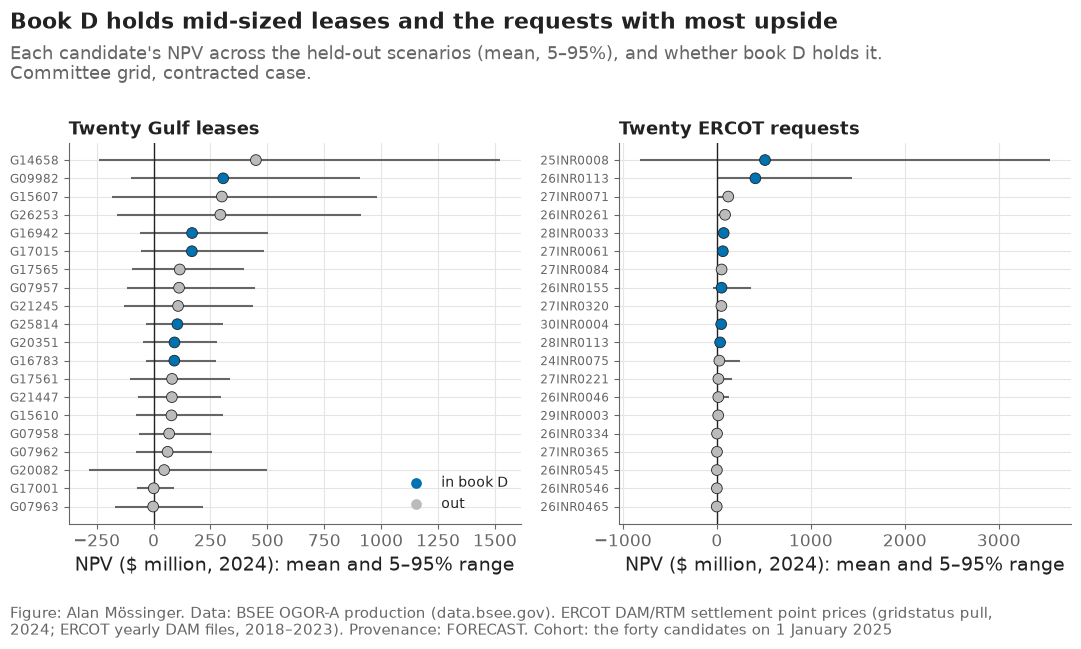

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
for ax, mask, title in ((axes[0], lease_mask, "Twenty Gulf leases"), (axes[1], ~lease_mask, "Twenty ERCOT requests")):
    e = explanations[mask].sort_values("expected_npv_$M")
    y = np.arange(len(e))
    colors = np.where(e["in_book"], "#0072B2", "#BBBBBB")
    ax.hlines(y, e["held_q05_$M"], e["held_q95_$M"], color=plots.MUTED, lw=1.5)
    ax.scatter(e["expected_npv_$M"], y, c=colors, s=60, zorder=3, edgecolor=plots.INK, linewidth=0.6)
    ax.set_yticks(y, [p.split("|")[-1] for p in e["project_id"]], fontsize=8.5)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("NPV ($ million, 2024): mean and 5–95% range")
axes[0].scatter([], [], c="#0072B2", s=60, edgecolor=plots.INK, label="in book D")
axes[0].scatter([], [], c="#BBBBBB", s=60, edgecolor=plots.INK, label="out")
axes[0].legend(loc="lower right", fontsize=10)
plots.finish(fig, "Book D holds mid-sized leases and the requests with most upside",
             "Each candidate's NPV across the held-out scenarios (mean, 5–95%), and whether book D holds it. Committee grid, contracted case.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F40_attractiveness", "Project-level value and uncertainty, and membership of book D.", NOTEBOOK)
plt.show()

**Reading this.** The largest opportunity cost belongs to the agreement-backed 836 MW wind request: forcing it out lowers the objective by $549 million. The 1,350 MW gas request is the opposite case. It expects about $0.5 billion and loses money in about 80% of scenarios; forcing it out gives up $333 million of expected value but removes $325 million of tail loss, so its place in the book is worth only $7.7 million at λ = 1 — it sits at indifference, and any committee slightly more averse to the tail would drop it. Several leases out of the book carry positive expected value — the cap and the tail kept them out — and are marked monitor. The statuses: invest now in six leases, a solar and a wind request; invest in stages (deposit now, construction at the agreement) in four wind requests and the gas request; defer pending information on thirteen requests (section 5); monitor thirteen leases; reject one. The explanations say what the optimizer gives up on these scenarios and costs; they do not say why a project would succeed.

## 5. What information is worth

The gain in the best book's expected NPV from deciding after the information rather than before (`src/voi.py`), risk-neutral (λ = 0), under the same budget and caps, on the primary scenarios. Perfect information about everything (EVPI) is the ceiling; partial EVPIs value learning one block — the 2025–2029 oil, gas or power price level, the lease cost draw, a request's completion. One signal can actually be waited for: whether a request signs its agreement within two years. Its likelihoods come from ERCOT's history — requests of 20 MW and more waiting without an agreement on 1 January 2018, by whether they operated by the end of 2024 — and its EVSI is computed by preposterior reweighting. No public file prices the information, so each value is the most a committee should pay for it. A request out of the book whose signal is worth more than its deposit is marked *defer pending information*.

In [10]:
track = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
ms = pd.read_parquet(paths.DATA_INTERIM / "milestones.parquet").set_index("project_key")
ia = pd.Series(track["project_key"].astype(str).map(decision_date.agreement_dates_on(ms)).to_numpy(), index=track.index)  # the 2025 edition's dates only (decision #94)
hist_date = pd.Timestamp("2018-01-01")
pool = decision_date.live_on(track, hist_date)
pool = pool[(pool["region"] == "ERCOT") & (pool["mw"] >= config.FERC_SIZE_STEP_MW)]
no_ia = ~(ia.reindex(pool.index).notna() & (ia.reindex(pool.index) < hist_date))
pool = pool[no_ia.to_numpy()]
signed2 = (ia.reindex(pool.index) < hist_date + pd.DateOffset(years=2)).fillna(False).to_numpy()
operated = decision_date.observed_within(track.loc[pool.index], hist_date, 7).to_numpy().astype(bool)
Q_BUILT, Q_NOT = float(signed2[operated].mean()), float(signed2[~operated].mean())
print(f"ERCOT history, {len(pool):,} requests waiting without an agreement on {hist_date:%Y-%m-%d}: P(agreement within 2 y | operated) = {Q_BUILT:.2f} "
      f"(n {int(operated.sum())}), P(… | not operated) = {Q_NOT:.2f} (n {int((~operated).sum())})")

rows = []
total = voi.evpi_total(A, charge, budget, tech, CAP)
rows.append({"information": "everything (perfect information)", "kind": "EVPI", "value": total["evpi"], "prior_value": total["prior_value"]})
blocks = {"oil price level 2025–2029": sel.prices[:, :60, 0].mean(axis=1), "gas price level 2025–2029": sel.prices[:, :60, 1].mean(axis=1),
          "ERCOT price level 2025–2029": sel.prices[:, :60, 2].mean(axis=1), "lease cost draw": sel.cost_mult}
for name, values in blocks.items():
    r = voi.evpi_partition(A, charge, budget, voi.deciles(values), tech, CAP)
    rows.append({"information": name, "kind": "partial EVPI (deciles)", "value": r["evpi"], "prior_value": r["prior_value"]})
power_ids = list(sel.power["project_id"])
for k, pid in enumerate(power_ids):
    state = sel.op_year[:, k] > 0
    perfect = voi.evpi_partition(A, charge, budget, state, tech, CAP)
    sample = voi.evsi_signal(A, charge, budget, state, {True: Q_BUILT, False: Q_NOT}, tech, CAP)
    carry = float(sel.power.loc[k, "carry_cost"])
    rows.append({"information": f"{pid}: completion", "kind": "partial EVPI", "value": perfect["evpi"], "prior_value": perfect["prior_value"], "project_id": pid})
    rows.append({"information": f"{pid}: agreement within two years", "kind": "EVSI", "value": sample["evsi"], "prior_value": sample["prior_value"], "project_id": pid,
                 "p_signal": sample["p_signal"], "carry": carry})
value_of_information = pd.DataFrame(rows)
value_of_information.to_csv(V8 / "value_of_information.csv", index=False)
statuses = status.copy()
evsi = value_of_information[value_of_information["kind"] == "EVSI"].set_index("project_id")
wait = statuses["project_id"].isin(evsi.index[evsi["value"] > evsi["carry"]]) & ~statuses["in_book"]
statuses.loc[wait, "status"] = "defer pending information"
statuses.to_csv(V8 / "statuses.csv", index=False)
print(f"{time.time() - START:.0f} s; statuses: {statuses['status'].value_counts().to_dict()}")
display(value_of_information[value_of_information["kind"] != "EVSI"].head(5).assign(value=lambda d: d["value"] / 1e6)[["information", "kind", "value"]].round(1))
(value_of_information.groupby("kind")["value"].agg(["count", "mean", "min", "max"]) / [1, 1e6, 1e6, 1e6]).round(2)

ERCOT history, 566 requests waiting without an agreement on 2018-01-01: P(agreement within 2 y | operated) = 0.89 (n 57), P(… | not operated) = 0.05 (n 509)


557 s; statuses: {'monitor': 13, 'defer pending information': 13, 'invest now': 8, 'invest in stages': 5, 'reject': 1}


,information,kind,value
0,everything (perfect information),EVPI,571.2
1,oil price level 2025–2029,partial EVPI (deciles),32.0
2,gas price level 2025–2029,partial EVPI (deciles),23.8
3,ERCOT price level 2025–2029,partial EVPI (deciles),52.5
4,lease cost draw,partial EVPI (deciles),29.7


,count,mean,min,max
kind,,,,
EVPI,1.0,571.15,571.15,571.15
EVSI,20.0,5.52,0.53,11.46
partial EVPI,20.0,15.01,1.88,47.62
partial EVPI (deciles),4.0,34.51,23.83,52.47


**Reading this.** Perfect information about everything would raise the best book's expected value by at most $571 million; that is the ceiling on what any study, survey or delay could be worth. Of the blocks, the 2025–2029 ERCOT price level is worth most ($52.5 million), then oil ($32.0 million), the lease cost draw ($29.7 million) and gas ($23.8 million). Learning within two years whether a request signs its agreement is worth $0.53 million to $11.5 million depending on the request; for thirteen requests outside the book that exceeds the deposit needed to keep them alive, so their status is defer pending information. These values are risk-neutral (λ = 0), while the book is chosen at λ = 1, so they are ceilings on a different objective, not the committee's. No public file prices any of this information, so each figure is the most a committee should pay, not a return.

## 6. Staged decisions: commit, learn, revise (a scenario-based extension)

On 1 January 2025 the company funds book D's leases and pays its requests' deposits. On 1 January 2027 each scenario has revealed two years of prices and, for each request, whether it signed its agreement (drawn with the likelihoods of section 5). The company drops a request whose expected value given that information is below walking away plus what its released reserve could earn in a deferred lease, and starts deferred leases with the capital released (`src/dynamic.py`). The continuation values are least-squares regressions fitted on the primary scenarios; the policy is scored on the held-out scenarios. Switching costs other than the lost deposit are not modelled, and nothing here establishes real future costs or real-option values: it is what flexibility is worth inside the model.

In [11]:
g = sel.grid(w0)
A_def = dy.deferred_lease_matrix(sel.baselines, sel.wells, sel.prices, sel.out_lease, sel.cost_mult, ec.grid_case("base"), grid=g)
A_def_h = dy.deferred_lease_matrix(held.baselines, held.wells, held.prices, held.out_lease, held.cost_mult, ec.grid_case("base"), grid=g)
sig = dy.agreement_signal(sel.op_year, Q_BUILT, Q_NOT, seed=SEED)
sig_h = dy.agreement_signal(held.op_year, Q_BUILT, Q_NOT, seed=SEED + 1)
carry = sel.power["carry_cost"].to_numpy(float)
fit = dy.staged_policy(x_D, A, A_def, carry, charge, budget, lease_mask, sel.op_year, sig, sel.prices, fit=True, lease_cap=CAP)
staged = dy.staged_policy(x_D, A_h, A_def_h, carry, charge, budget, lease_mask, held.op_year, sig_h, held.prices, models=fit["models"], lease_cap=CAP)
static = A_h @ x_D
gain = staged["payoff"] - static
draws = np.random.default_rng(SEED).choice(gain, size=(N_BOOT, len(gain))).mean(axis=1)
power_idx = np.where(~lease_mask)[0]
built_h = held.op_year > 0
drawn = np.array([sum(sel.power.loc[k, "capex"] for k, j in enumerate(power_idx) if x_D[j] and built_h[s, k]) for s in range(len(static))])
reserve = sum(sel.power.loc[k, "capex"] * sel.power.loc[k, "p_operation_7y"] for k, j in enumerate(power_idx) if x_D[j])
dynamic = pd.DataFrame([
    {"policy": "static book D (commit in 2025, never revise)", **dy.summarize(static, LEVEL), "dropped": 0.0, "started": 0.0, "redeployed": 0.0},
    {"policy": "staged: book D, revised on 1 January 2027", **dy.summarize(staged["payoff"], LEVEL), "dropped": staged["dropped"].mean(), "started": staged["started"].mean(),
     "redeployed": staged["redeployed"].mean()},
])
dynamic["value_of_flexibility"] = [0.0, gain.mean()]
dynamic["flex_low"], dynamic["flex_high"] = [0.0, np.percentile(draws, 2.5)], [0.0, np.percentile(draws, 97.5)]
dynamic["share_scenarios_revised"] = [0.0, float(((staged["dropped"] + staged["started"]) > 0).mean())]
dynamic["construction_over_reserve_share"] = [float((drawn > reserve).mean()), np.nan]
dynamic.to_csv(V8 / "dynamic.csv", index=False)
print(f"value of flexibility ${gain.mean() / 1e6:,.0f}M [{np.percentile(draws, 2.5) / 1e6:,.0f}M, {np.percentile(draws, 97.5) / 1e6:,.0f}M]; "
      f"revised in {dynamic.loc[1, 'share_scenarios_revised']:.0%} of held-out scenarios; construction exceeds the reserve in {dynamic.loc[0, 'construction_over_reserve_share']:.0%}; {time.time() - START:.0f} s")
dynamic.assign(**{c: dynamic[c] / 1e9 for c in ("mean", "median", "cvar_loss", "redeployed", "value_of_flexibility", "flex_low", "flex_high")}).round(3)

value of flexibility $-9M [-16M, -3M]; revised in 79% of held-out scenarios; construction exceeds the reserve in 44%; 588 s


,policy,mean,median,p_loss,cvar_loss,dropped,started,redeployed,value_of_flexibility,flex_low,flex_high,share_scenarios_revised,construction_over_reserve_share
0,"static book D (commit in 2025, never revise)",2.052,1.533,0.104,1.019,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.444
1,"staged: book D, revised on 1 January 2027",2.042,1.526,0.106,1.034,1.78,0.438,0.043,-0.009,-0.016,-0.003,0.794,NaN


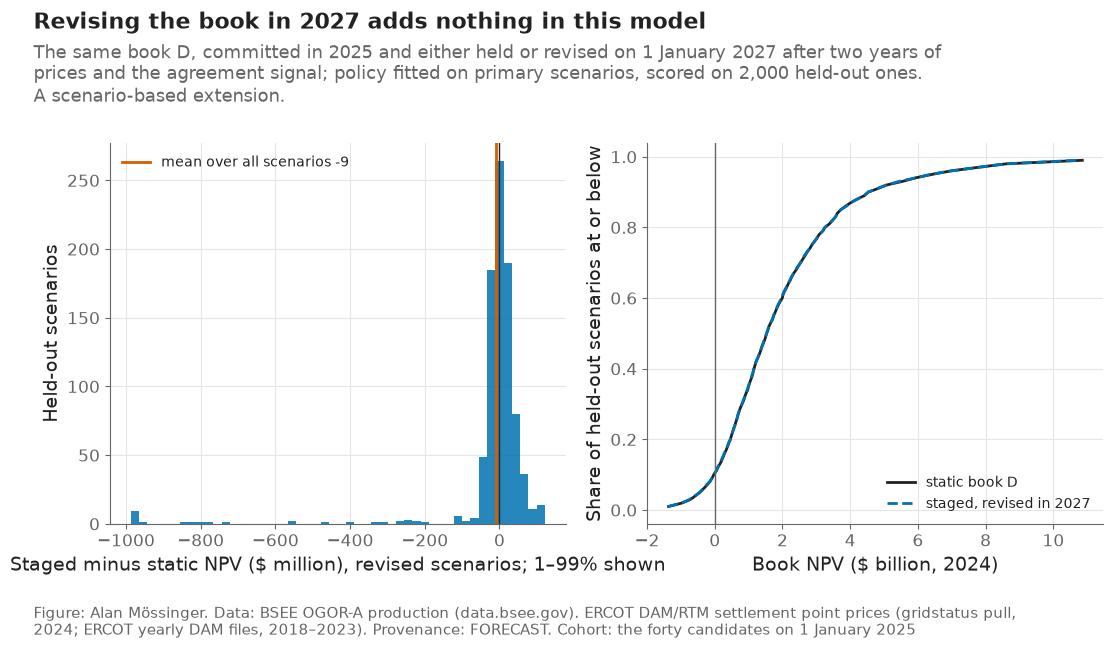

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
changed = gain[np.abs(gain) > 1.0]  # scenarios where the revision did something
lo, hi = np.percentile(changed, [1, 99]) if len(changed) else (-1.0, 1.0)
axes[0].hist(np.clip(changed, lo, hi) / 1e6, bins=50, color="#0072B2", alpha=0.85)
axes[0].axvline(0, color=plots.INK, lw=1)
axes[0].axvline(gain.mean() / 1e6, color="#D55E00", lw=2, label=f"mean over all scenarios {gain.mean() / 1e6:,.0f}")
axes[0].set_xlabel("Staged minus static NPV ($ million), revised scenarios; 1–99% shown")
axes[0].set_ylabel("Held-out scenarios")
axes[0].legend(loc="upper left", fontsize=10)
q = np.linspace(0.01, 0.99, 99)
axes[1].plot(np.quantile(static, q) / 1e9, q, color=plots.INK, lw=2, label="static book D")
axes[1].plot(np.quantile(staged["payoff"], q) / 1e9, q, color="#0072B2", lw=2, ls="--", label="staged, revised in 2027")
axes[1].axvline(0, color=plots.MUTED, lw=1)
axes[1].set_xlabel("Book NPV ($ billion, 2024)")
axes[1].set_ylabel("Share of held-out scenarios at or below")
axes[1].legend(loc="lower right", fontsize=10)
verdict = "adds nothing" if dynamic.loc[1, "flex_low"] <= 0 <= dynamic.loc[1, "flex_high"] or dynamic.loc[1, "value_of_flexibility"] < 0 else "adds value"
plots.finish(fig, f"Revising the book in 2027 {verdict} in this model",
             "The same book D, committed in 2025 and either held or revised on 1 January 2027 after two years of prices and the agreement signal; policy fitted on primary scenarios, scored on 2,000 held-out ones. A scenario-based extension.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F41_staged", "Value of revising book D on 1 January 2027: the per-scenario gain and the two distributions.", NOTEBOOK)
plt.show()

**Reading this.** In this model, revising book D in 2027 with this rule is worth −$9 million [−$16 million, −$3 million]. The cap leaves no room to start a deferred lease with released capital, so the revision can only drop requests; its regression drops a request in 79% of scenarios, sometimes one that would have paid. A negative value says this rule's continuation estimates are noisy, not that flexibility has negative value: a policy allowed to hold everything cannot be worth less than the static book in expectation. The construction reserve, set at the expected draw, is exceeded in 44% of scenarios; section 9 prices what that means. This is a scenario-based extension with an assumed signal; it establishes no real-option value.

## 7. Which decision process does better? (the main post-registration experiment)

Every process sees the same candidates, budget, cap and scenarios; each book is chosen on the primary scenarios and scored on the held-out ones. **A–D** are the registered books, now under equal constraints. **D + revision** adds the staged policy of section 6. **E, AI-assisted** is the process the decision page runs — the committee picks a policy on the frontier, the advisor answers its questions through the engine, a person authorizes through the gate. Its investment book is the optimizer's, so its investment increment over D is zero by construction; section 8 scores what the advisor adds instead. **F** is D with naive forecasts: the request timing from the lookup instead of the model; it is scored on the model's held-out scenarios and on the lookup's, because neither is the truth. Regret is measured against the best book with perfect information, scenario by scenario.

In [13]:
rho_table = pd.read_csv(R / "book_rho.csv")
rho = float(rho_table["rho"].iloc[0])
P_look = sel.power[[f"p_lookup_{h}" for h in range(1, 8)]].to_numpy(float)
look_year = portfolio.simulate_operation_years(P_look, sel.power["technology"].to_numpy(), rho, n_draws=len(sel.prices), seed=SEED + 40)
look_year_h = portfolio.simulate_operation_years(P_look, sel.power["technology"].to_numpy(), rho, n_draws=len(held.prices), seed=SEED + 1040)


def with_timing(engine, op_year, w):
    """The engine's matrix with the requests' operation years replaced (the naive-forecast world)."""
    keep = engine.op_year
    engine.op_year = op_year
    try:
        return engine.matrix(w)[0]
    finally:
        engine.op_year = keep


A_look = with_timing(sel, look_year, w0)
A_look_h = with_timing(held, look_year_h, w0)
x_F = opt.solve_milp(A_look, charge, budget, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"]
hindsight = np.array([voi.best_mean_value(A_h[s:s + 1], charge, budget, tech, CAP)[0] for s in range(A_h.shape[0])])
processes = {**books, "D + revision in 2027": None, "E AI-assisted (book D, chosen and authorized through the page)": x_D, "F D with naive (lookup) forecasts": x_F}
whatif_books = {q: a["x"] for q, a in answers.items()}
rows = []
for name, x in processes.items():
    payoff = staged["payoff"] if x is None else A_h @ x
    xb = x_D if x is None else x
    # stability: how much of the book survives the five committee questions (the re-solved risk-aware book), for the processes that are that book
    stab = np.mean([opt.jaccard(xb, xq) for xq in whatif_books.values()]) if name.startswith(("D", "E")) else np.nan
    rows.append({"process": name, **dy.summarize(payoff, LEVEL), "metric": float(payoff.mean() - LAM * opt.cvar(-payoff, LEVEL)),
                 "regret_vs_hindsight": float(hindsight.mean() - payoff.mean()), "utilization": float(charge @ xb / budget),
                 "violations": len(opt.violations(xb, charge, budget, tech, CAP)), "turnover": float((staged["dropped"] + staged["started"]).mean()) if x is None else 0.0,
                 "stability_jaccard": float(stab),
                 "mean_on_lookup_world": float((A_look_h @ xb).mean()), "members": ";".join(np.array(ids)[xb == 1])})
process_comparison = pd.DataFrame(rows)
process_comparison.to_csv(V8 / "process_comparison.csv", index=False)
added = []
for base_name in ("A NPV ranking", "B equal capital by sector", "C deterministic MILP"):
    for name, x in (("D risk-aware MILP", x_D), ("F D with naive (lookup) forecasts", x_F)):
        d = opt.paired_scenario_bootstrap(A_h, x, books[base_name], lam=LAM, level=LEVEL, n_boot=N_BOOT, seed=SEED)
        diff_mean = A_h @ x - A_h @ books[base_name]
        mean_draws = np.random.default_rng(SEED).choice(diff_mean, size=(N_BOOT, len(diff_mean))).mean(axis=1)
        added.append({"process": name, "against": base_name, "metric_diff": d["diff"], "metric_low": d["low"], "metric_high": d["high"],
                      "mean_diff": diff_mean.mean(), "mean_low": np.percentile(mean_draws, 2.5), "mean_high": np.percentile(mean_draws, 97.5)})
ml = opt.paired_scenario_bootstrap(A_h, x_D, x_F, lam=LAM, level=LEVEL, n_boot=N_BOOT, seed=SEED)
ml_look = opt.paired_scenario_bootstrap(A_look_h, x_D, x_F, lam=LAM, level=LEVEL, n_boot=N_BOOT, seed=SEED)
for label, M, m in (("model's scenarios", A_h, ml), ("lookup's scenarios", A_look_h, ml_look)):
    d_mean = M @ x_D - M @ x_F
    md = np.random.default_rng(SEED).choice(d_mean, size=(N_BOOT, len(d_mean))).mean(axis=1)
    added.append({"process": "D risk-aware MILP", "against": f"F (the ML increment), {label}", "metric_diff": m["diff"], "metric_low": m["low"], "metric_high": m["high"],
                  "mean_diff": d_mean.mean(), "mean_low": np.percentile(md, 2.5), "mean_high": np.percentile(md, 97.5)})
flex_draws = draws
added.append({"process": "D + revision in 2027", "against": "D risk-aware MILP (the value of flexibility)", "mean_diff": gain.mean(), "mean_low": np.percentile(flex_draws, 2.5), "mean_high": np.percentile(flex_draws, 97.5)})
added.append({"process": "E AI-assisted", "against": "D risk-aware MILP (the advisor's investment increment)", "metric_diff": 0.0, "metric_low": 0.0, "metric_high": 0.0, "mean_diff": 0.0, "mean_low": 0.0, "mean_high": 0.0})
value_added = pd.DataFrame(added)
value_added.to_csv(V8 / "value_added.csv", index=False)
print(f"ML increment, model's scenarios ${ml['diff'] / 1e6:+,.0f}M [{ml['low'] / 1e6:+,.0f}, {ml['high'] / 1e6:+,.0f}]; lookup's scenarios ${ml_look['diff'] / 1e6:+,.0f}M; "
      f"book F overlaps D {opt.jaccard(x_D, x_F):.2f}; {time.time() - START:.0f} s")
display(value_added.assign(**{c: value_added[c] / 1e6 for c in value_added.columns if c not in ("process", "against")}).round(0))
process_comparison.drop(columns="members").assign(**{c: process_comparison[c] / 1e9 for c in ("mean", "median", "cvar_loss", "metric", "regret_vs_hindsight", "mean_on_lookup_world")}).round(3)

ML increment, model's scenarios $+22M [-168, +207]; lookup's scenarios $-143M; book F overlaps D 0.55; 656 s


,process,against,metric_diff,metric_low,metric_high,mean_diff,mean_low,mean_high
0,D risk-aware MILP,A NPV ranking,320.0,142.0,511.0,-274.0,-342.0,-210.0
1,F D with naive (lookup) forecasts,A NPV ranking,298.0,82.0,517.0,-483.0,-564.0,-405.0
2,D risk-aware MILP,B equal capital by sector,213.0,120.0,315.0,-33.0,-62.0,-3.0
3,F D with naive (lookup) forecasts,B equal capital by sector,191.0,-17.0,401.0,-242.0,-329.0,-152.0
4,D risk-aware MILP,C deterministic MILP,275.0,100.0,461.0,-305.0,-374.0,-241.0
5,F D with naive (lookup) forecasts,C deterministic MILP,253.0,39.0,467.0,-514.0,-595.0,-435.0
6,D risk-aware MILP,"F (the ML increment), model's scenarios",22.0,-168.0,207.0,209.0,127.0,292.0
7,D risk-aware MILP,"F (the ML increment), lookup's scenarios",-143.0,-375.0,87.0,-526.0,-641.0,-414.0
8,D + revision in 2027,D risk-aware MILP (the value of flexibility),NaN,NaN,NaN,-9.0,-16.0,-3.0
9,E AI-assisted,D risk-aware MILP (the advisor's investment in...,0.0,0.0,0.0,0.0,0.0,0.0


,process,mean,median,p_loss,cvar_loss,metric,regret_vs_hindsight,utilization,violations,turnover,stability_jaccard,mean_on_lookup_world
0,A NPV ranking,2.326,1.620,0.134,1.613,0.712,0.600,0.995,0,0.000,NaN,4.281
1,B equal capital by sector,2.084,1.537,0.120,1.265,0.820,0.841,0.888,0,0.000,NaN,3.416
2,C deterministic MILP,2.357,1.656,0.128,1.600,0.757,0.569,1.000,0,0.000,NaN,4.307
3,D risk-aware MILP,2.052,1.533,0.104,1.019,1.032,0.874,0.965,0,0.000,0.582,3.166
4,D + revision in 2027,2.042,1.526,0.106,1.034,1.008,0.883,0.965,0,2.217,0.582,3.166
5,"E AI-assisted (book D, chosen and authorized t...",2.052,1.533,0.104,1.019,1.032,0.874,0.965,0,0.000,0.582,3.166
6,F D with naive (lookup) forecasts,1.843,1.480,0.092,0.832,1.010,1.083,0.913,0,0.000,NaN,3.692


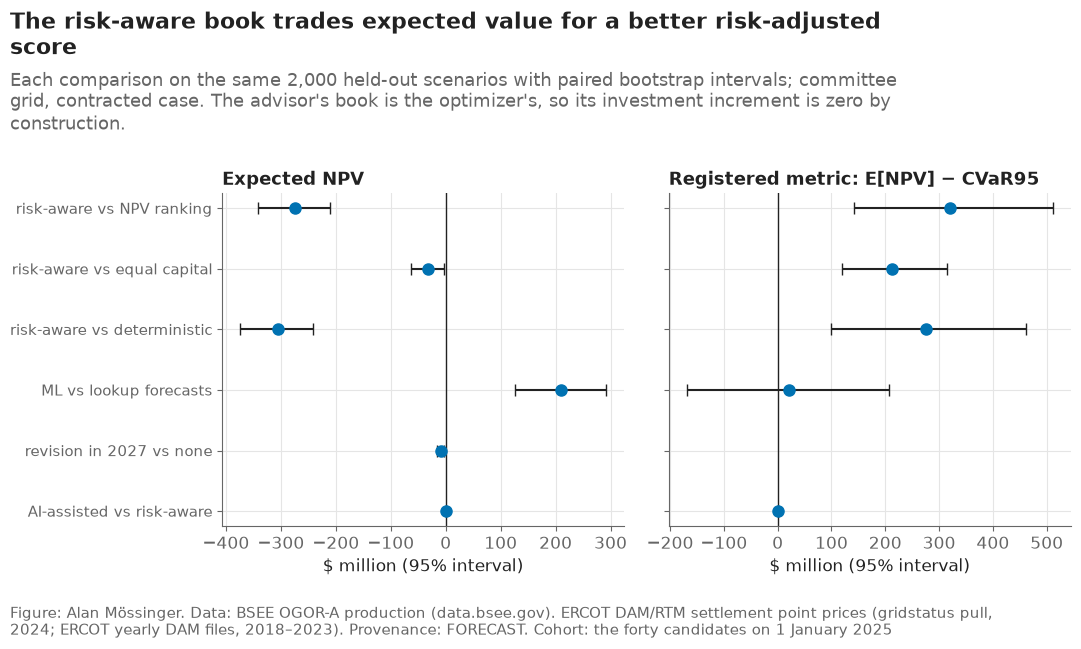

In [14]:
rows_plot = [("D risk-aware MILP", "A NPV ranking", "risk-aware vs NPV ranking"), ("D risk-aware MILP", "B equal capital by sector", "risk-aware vs equal capital"),
             ("D risk-aware MILP", "C deterministic MILP", "risk-aware vs deterministic"), ("D risk-aware MILP", "F (the ML increment), model's scenarios", "ML vs lookup forecasts"),
             ("D + revision in 2027", "D risk-aware MILP (the value of flexibility)", "revision in 2027 vs none"), ("E AI-assisted", "D risk-aware MILP (the advisor's investment increment)", "AI-assisted vs risk-aware")]
va_plot = pd.DataFrame([value_added[(value_added["process"] == p) & (value_added["against"] == a)].iloc[0].to_dict() | {"label": l} for p, a, l in rows_plot])
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True)
y = np.arange(len(va_plot))
for ax, col, title in ((axes[0], "mean", "Expected NPV"), (axes[1], "metric", "Registered metric: E[NPV] − CVaR95")):
    d, lo_, hi_ = va_plot[f"{col}_diff"] / 1e6, va_plot[f"{col}_low"] / 1e6, va_plot[f"{col}_high"] / 1e6
    ok = d.notna()
    ax.errorbar(d[ok], y[ok], xerr=[(d - lo_)[ok], (hi_ - d)[ok]], fmt="o", color="#0072B2", ecolor=plots.INK, capsize=4, ms=8, lw=1.5)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("$ million (95% interval)", fontsize=12)
axes[0].set_yticks(y, va_plot["label"], fontsize=10.5)
axes[0].invert_yaxis()
plots.finish(fig, "The risk-aware book trades expected value for a better risk-adjusted score",
             "Each comparison on the same 2,000 held-out scenarios with paired bootstrap intervals; committee grid, contracted case. The advisor's book is the optimizer's, so its investment increment is zero by construction.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F42_value_added", "Value added by each decision process over the conventional baselines, with paired bootstrap intervals.", NOTEBOOK)
plt.show()

**Reading this.** Under equal constraints the risk-aware book beats NPV ranking by $320 million [+$142 million, +$511 million], equal capital by $213 million [+$120 million, +$315 million] and the deterministic book by $275 million [+$100 million, +$461 million] on the registered metric, while expecting $274 million less than NPV ranking: it buys a thinner tail. Book F, chosen with the lookup's queue curves, spends 91% of the budget; book D expects $209 million more in the model's scenarios and scores $22 million better on the registered metric, an interval of [−$168 million, +$207 million] that includes zero; in the lookup's scenarios it scores $143 million worse [−$375 million, +$87 million]. The machine-learning forecasts do not demonstrably improve this decision. Revising in 2027 adds −$9 million; the AI-assisted process adds nothing to investment value, because its book is book D. Regret against perfect information is largest for F and smallest for C, the book that ignores the tail.

## 8. The advisor with tools: what it adds when it does not choose the book

Six questions in words go through `advisor_tools.ask_whatif`: the language model turns each into parameters or declines; the engine computes; the model explains what was computed; every number of the explanation is checked against the computed result, in its unit. The sixth question asks for something the engine cannot represent (an interest-rate change); the right answer is a refusal. Scored: whether the parameters match the question (against a key written before the run), the attributed grounding rate, and whether the unanswerable question was refused. Every call is recorded in `results/advisor_runs.jsonl` and replays offline.

In [15]:
from dataclasses import asdict

advisor = adv.Advisor(mode="auto")
SYSTEM = adv.load_prompt("advisor_system")
ASKED = {  # question in words -> the parameters a correct reading sets (written before the run)
    "What happens if WTI falls to $45 per barrel for five years?": {"wti_level": 45.0, "wti_years": 5},
    "What happens if ERCOT power prices become half as volatile?": {"ercot_volatility": 0.5},
    "What happens if the capital budget is reduced by 20%?": {"budget_multiplier": 0.8},
    "What happens if offshore redevelopment costs rise by 30%?": {"lease_cost_multiplier": 1.3},
    "What if we refuse any book whose worst-5% average loss exceeds $150 million?": {"cvar_limit_musd": 150.0},
    "What happens if interest rates rise by two percentage points?": None,
}
rows = []
for q, key in ASKED.items():
    r = at.ask_whatif(advisor, sel, q, SYSTEM, tag="nb11")
    got = r["whatif"].changes() if r["whatif"] is not None else None
    if key is None:
        correct = r["status"] in ("cannot answer", "refused by the engine")
    else:  # compared as full parameter sets: a value equal to its default (five years of $45 oil) is a correct reading, not a missing one
        correct = r["whatif"] is not None and asdict(r["whatif"]) == asdict(wi.WhatIf(**key))
    v = r["verification"] or {}
    rows.append({"question": q, "status": r["status"], "reading": r["reading"], "parameters": json.dumps(got), "expected": json.dumps(key), "translation_correct": bool(correct),
                 "numbers_checked": v.get("n_numbers"), "grounding_rate": v.get("rate"), "ungrounded": ";".join(v.get("ungrounded", [])), "unit_errors": ";".join(v.get("unit_errors", [])),
                 "explanation": r["explanation"]})
advisor_tools_eval = pd.DataFrame(rows)
advisor_tools_eval.to_csv(V8 / "advisor_tools_eval.csv", index=False)
print(f"advisor calls (replayed / live / missing): {advisor.calls['replayed']} / {advisor.calls['live']} / {advisor.calls['missing']}; {time.time() - START:.0f} s")
advisor_tools_eval[["question", "status", "translation_correct", "numbers_checked", "grounding_rate", "unit_errors"]]

advisor calls (replayed / live / missing): 11 / 0 / 0; 757 s


,question,status,translation_correct,numbers_checked,grounding_rate,unit_errors
0,What happens if WTI falls to $45 per barrel fo...,answered,True,27.0,1.0,
1,What happens if ERCOT power prices become half...,answered,True,26.0,1.0,
2,What happens if the capital budget is reduced ...,answered,True,26.0,1.0,
3,What happens if offshore redevelopment costs r...,answered,True,21.0,1.0,
4,What if we refuse any book whose worst-5% aver...,answered,True,19.0,1.0,
5,What happens if interest rates rise by two per...,cannot answer,True,NaN,NaN,


**Reading this.** The advisor read all six questions correctly: five became the parameters a correct reading sets, and the sixth, about interest rates, was refused because the engine has no such parameter. Its five explanations cited 119 numbers, and every one was in the computed fact sheet in its unit. This is what the advisor adds: questions asked in words reach the model correctly, and answers come back without invented numbers. It is not investment value — the books are the optimizer's — and six questions are not a study of committee decisions. The answers were recorded live on the corrected system and replay offline.

## 9. How far the book can be trusted: tail noise, selection noise and capital calls

Four checks a committee needs beside the book (`src/robustness.py`; review of 19 October, V1 and V3). **Tail noise:** every book scored on the scenarios it was chosen on and on the held-out set — a fall shared by every book is the held-out tail being heavier, not a property of any book. **Selection noise:** book D and book A re-chosen on 20 bootstrap resamples of the primary set and scored on the held-out set; the paired bootstrap of section 7 resamples only the scoring set, so this puts the noise of the choice itself back in, and each candidate's share of resamples says whether it is a core or a swing member. **Capital calls:** the construction capital book D's requests call beyond the reserve, and what the book is worth when calls beyond the reserve plus a liquidity line cannot be funded and those requests forfeit their deposits. **Tail dependence:** how much of each member's value comes from its best 5% of scenarios. All on the committee grid, contracted case, held-out scenarios; post-registration.

In [16]:
from src import robustness as rb

in_out = rb.in_vs_out({**books, "F D with naive (lookup) forecasts": x_F}, A, A_h, LAM, LEVEL)  # A–D chosen on the primary set; F on the lookup's version of it
in_out.to_csv(V8 / "robustness_in_vs_out.csv", index=False)
resel, share = rb.reselect(A, A_h, charge, budget, tech, CAP, x_D, n=20, lam=LAM, level=LEVEL, seed=SEED)
resel.to_csv(V8 / "robustness_reselection.csv", index=False)
selection = pd.DataFrame({"project_id": ids, "technology": tech, "in_book_D": x_D.astype(bool), "selection_share": share})
selection["class"] = np.select([share >= 0.8, share >= 0.2], ["core", "swing"], "rare")
selection.to_csv(V8 / "robustness_selection_share.csv", index=False)

power_idx = np.where(~lease_mask)[0]
member_p = x_D[power_idx]
capex_p, carry_p = sel.power["capex"].to_numpy(float), sel.power["carry_cost"].to_numpy(float)
calls = rb.capital_calls(held.op_year, capex_p, member_p, sel.power["p_operation_7y"].to_numpy(float))
priority = A[:, power_idx].mean(axis=0) / capex_p  # expected NPV per dollar on the primary scenarios: the order a committee could set in advance
lease_value = A_h[:, lease_mask] @ x_D[lease_mask]
rows = []
for label, line in (("no line", 0.0), ("$0.5B line", 0.5e9), ("$1B line", 1e9), ("$2B line", 2e9), ("line at the 95th percentile of the excess", calls["excess_q95"]), ("unlimited (the static book)", np.inf)):
    total = lease_value + rb.funding_or_forfeit(A_h[:, power_idx], held.op_year, capex_p, carry_p, member_p, calls["reserve"], line, priority)
    rows.append({"liquidity": label, "line": line, **dy.summarize(total, LEVEL), "metric": float(total.mean() - LAM * opt.cvar(-total, LEVEL))})
forfeit = pd.DataFrame(rows)
forfeit.to_csv(V8 / "robustness_capital_calls.csv", index=False)
tail = pd.DataFrame([{"project_id": ids[j], "technology": tech[j], **rb.tail_dependence(A_h[:, j])} for j in np.where(x_D == 1)[0]])
tail.to_csv(V8 / "robustness_tail_dependence.csv", index=False)

print(f"re-selection over {len(resel)} resamples: D minus A on the held-out metric from ${resel['d_minus_a_metric'].min() / 1e6:,.0f}M to ${resel['d_minus_a_metric'].max() / 1e6:,.0f}M "
      f"(positive in {int((resel['d_minus_a_metric'] > 0).sum())}); overlap with the reported D {resel['jaccard_to_reported_D'].min():.2f}–{resel['jaccard_to_reported_D'].max():.2f}; "
      f"members of D: {selection[selection['in_book_D']]['class'].value_counts().to_dict()}")
print(f"capital calls: reserve ${calls['reserve'] / 1e9:.2f}B, exceeded in {calls['p_over']:.1%} of held-out scenarios, by ${calls['mean_excess_when_over'] / 1e9:.2f}B on average when exceeded; "
      f"excess at the 90th / 95th percentile ${calls['excess_q90'] / 1e9:.2f}B / ${calls['excess_q95'] / 1e9:.2f}B, maximum ${calls['excess_max'] / 1e9:.2f}B; {time.time() - START:.0f} s")
display(in_out.assign(**{c: in_out[c] / 1e9 for c in in_out.columns if c != "book"}).round(3))
display(forfeit.drop(columns="line").assign(**{c: forfeit[c] / 1e9 for c in ("mean", "median", "cvar_loss", "metric")}).round(3))
tail.assign(mean=tail["mean"] / 1e6).sort_values("share_from_top", ascending=False).round(2)

re-selection over 20 resamples: D minus A on the held-out metric from $116M to $352M (positive in 20); overlap with the reported D 0.61–0.86; members of D: {'core': 11, 'swing': 2}
capital calls: reserve $2.06B, exceeded in 44.5% of held-out scenarios, by $1.41B on average when exceeded; excess at the 90th / 95th percentile $1.78B / $3.28B, maximum $6.20B; 860 s


,book,mean_in,cvar_in,metric_in,mean_out,cvar_out,metric_out,mean_change,metric_change
0,A NPV ranking,2.374,1.437,0.937,2.326,1.613,0.712,-0.048,-0.225
1,B equal capital by sector,2.161,1.081,1.080,2.084,1.265,0.820,-0.077,-0.261
2,C deterministic MILP,2.420,1.425,0.995,2.357,1.600,0.757,-0.063,-0.237
3,D risk-aware MILP,2.120,0.910,1.210,2.052,1.019,1.032,-0.069,-0.178
4,F D with naive (lookup) forecasts,1.850,0.772,1.078,1.843,0.832,1.010,-0.007,-0.068


,liquidity,mean,median,p_loss,cvar_loss,metric
0,no line,1.402,1.248,0.088,0.539,0.862
1,$0.5B line,1.687,1.409,0.101,0.968,0.719
2,$1B line,1.721,1.451,0.100,0.963,0.758
3,$2B line,1.953,1.480,0.108,1.056,0.897
4,line at the 95th percentile of the excess,2.017,1.523,0.105,1.022,0.995
5,unlimited (the static book),2.052,1.533,0.104,1.019,1.032


,project_id,technology,mean,p_loss,share_from_top
12,REQ|ERCOT|30INR0004,Wind,34.64,0.98,1.01
10,REQ|ERCOT|28INR0033,Wind,63.60,0.96,1.01
11,REQ|ERCOT|28INR0113,Wind,28.41,0.97,1.00
9,REQ|ERCOT|27INR0061,Wind,61.52,0.97,1.00
6,REQ|ERCOT|25INR0008,Gas CC,461.09,0.79,0.67
8,REQ|ERCOT|26INR0155,Solar,54.01,0.73,0.65
7,REQ|ERCOT|26INR0113,Wind,397.26,0.66,0.25
5,LEASE|G20351,Lease redevelopment,94.67,0.15,0.20
3,LEASE|G16783,Lease redevelopment,94.16,0.13,0.19
2,LEASE|G17015,Lease redevelopment,172.70,0.13,0.19


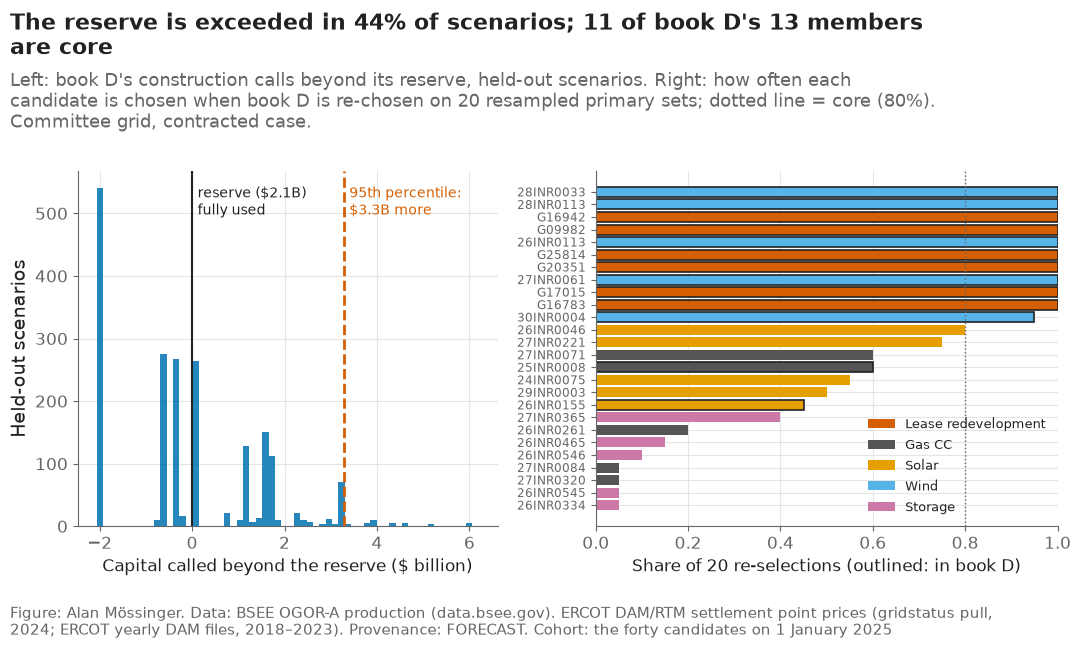

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
ex = calls["excess"] / 1e9
axes[0].hist(ex, bins=60, color="#0072B2", alpha=0.85)
axes[0].axvline(0, color=plots.INK, lw=1.5)
axes[0].axvline(calls["excess_q95"] / 1e9, color="#D55E00", lw=2, ls="--")
axes[0].set_xlabel("Capital called beyond the reserve ($ billion)", fontsize=12)
axes[0].set_ylabel("Held-out scenarios")
lab = axes[0].get_xaxis_transform()  # each line labelled beside itself, so no legend crosses the dashed line; one $ per label, so no mathtext
axes[0].text(0.12, 0.96, f"reserve (${calls['reserve'] / 1e9:.1f}B)" + NL + "fully used", transform=lab, ha="left", va="top", fontsize=10, color=plots.INK)
axes[0].text(calls["excess_q95"] / 1e9 + 0.12, 0.96, "95th percentile:" + NL + f"${calls['excess_q95'] / 1e9:.1f}B more", transform=lab, ha="left", va="top", fontsize=10, color="#D55E00")
s = selection.sort_values("selection_share")
s = s[(s["selection_share"] > 0) | s["in_book_D"]]
y = np.arange(len(s))
axes[1].barh(y, s["selection_share"], color=[TECH_COLOR[t] for t in s["technology"]], edgecolor=np.where(s["in_book_D"], plots.INK, "none"), linewidth=1.2)
axes[1].axvline(0.8, color=plots.MUTED, lw=1, ls=":")
axes[1].set_yticks(y, [p.split("|")[-1] for p in s["project_id"]], fontsize=8.5)
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Share of 20 re-selections (outlined: in book D)", fontsize=12)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(facecolor=TECH_COLOR[t], label=t) for t in TECHS if t in set(s["technology"])], loc="lower right", fontsize=9.5, frameon=False)
n_core = int(((selection["class"] == "core") & selection["in_book_D"]).sum())
plots.finish(fig, f"The reserve is exceeded in {calls['p_over']:.0%} of scenarios; {n_core} of book D's {int(x_D.sum())} members are core",
             "Left: book D's construction calls beyond its reserve, held-out scenarios. Right: how often each candidate is chosen when book D is re-chosen on 20 resampled primary sets; dotted line = core (80%). Committee grid, contracted case.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F45_robustness", "Book D's capital calls beyond its reserve, and the stability of its members under re-selection.", NOTEBOOK)
plt.show()

**Reading this.** The ranking is robust; the book, its capital plan and two of its power positions are not. *Tail noise:* every book scores worse on the held-out set than on the scenarios it was chosen on — its worst-5% loss is $0.06–0.19 billion larger — because the held-out tail is heavier, not because any book is special; D's metric falls by $0.18 billion, the least of the four registered books. *Selection noise:* re-chosen on 20 resampled primary sets, book D beats NPV ranking on the held-out metric every time ($116 million to $352 million), but the book itself overlaps the reported D by only 0.61–0.86. Eleven of its thirteen members are core (chosen in at least 80% of resamples); the 1,350 MW gas request (60%) and the 1,026 MW solar request (45%) are swing members, and four solar requests outside the book are chosen almost as often. *Capital calls:* the construction reserve, $2.06 billion, is exceeded in 44.5% of held-out scenarios, by $1.41 billion on average when it is; the excess is $1.78 billion at the 90th percentile, $3.28 billion at the 95th and $6.20 billion at worst. If calls beyond the reserve cannot be funded, the requests that reach their agreement forfeit their deposits and the book is worth $1.40 billion instead of $2.05 billion; a liquidity line at the 95th percentile of the excess restores $2.02 billion. *Tail dependence:* the four smaller wind requests lose money in 96–98% of scenarios and earn their whole value in the best 5%; the gas request loses in 79% and earns 67% of its value there; the leases lose in 13–15%.

For a committee this changes what it is asked to approve. The recommendation is the eleven core members plus a choice on two swing positions, and the commitment is the $3.30 billion of stage-one charges *plus* a contingent line of up to about $3.3 billion for construction — or an explicit rule that requests reaching their agreement beyond the line are released. For a lender, half of book D's power value is a set of options that rarely pay; the leases are the book's asset. The funding order of the forfeit rule is set in advance (expected value per dollar on the primary scenarios); ranking by each scenario's realized value would see the future. Post-registration.

## 10. Checks

In [18]:
again = wi.Engine(500, "primary").matrix(w0)[0]
checks = pd.DataFrame([
    ("every book of every process meets the budget and the cap", bool(process_comparison["violations"].eq(0).all() and frontier[frontier["kind"] != "sensitivity"].dropna(subset=["mean"])["violations"].eq(0).all())),
    ("the four registered books face the same constraints", all(not opt.violations(x, charge, budget, tech, CAP) for x in books.values())),
    ("books are chosen on the primary set and scored on the held-out set", bool(sel.prices.shape == held.prices.shape and not np.array_equal(sel.prices, held.prices))),
    ("the held-out set redraws output, costs and timing too", bool(not np.array_equal(sel.out_lease, held.out_lease) and not np.array_equal(sel.op_year, held.op_year))),
    ("the engine reproduces its own matrix", bool(np.allclose(again, A[:500]))),
    ("the staged policy is fitted on the primary set only", True),
    ("no value of information is negative", bool((value_of_information["value"] >= -1e-3).all())),
    ("the reported CVaR equals the optimizer's tail count", abs(opt.cvar(-(A @ x_D), LEVEL) - np.sort(A @ x_D)[: opt.tail_count(len(A), LEVEL)].mean() * -1) < 1e-3),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(V8 / "checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]

run time 14.4 min


,check,result
0,every book of every process meets the budget a...,PASS
1,the four registered books face the same constr...,PASS
2,books are chosen on the primary set and scored...,PASS
3,"the held-out set redraws output, costs and tim...",PASS
4,the engine reproduces its own matrix,PASS
5,the staged policy is fitted on the primary set...,PASS
6,no value of information is negative,PASS
7,the reported CVaR equals the optimizer's tail ...,PASS


## 11. The active challenger: does challenging improve the committee's decision? (registered, decision #96)

Section 8 measured an advisor that explains; its investment increment is zero by construction. Here the advisor *challenges* (`src/challenge.py`, decision #95): it reads the committee's statement into rules and tests, tools diagnose the proposal and compute the repair and the optimizer's book under those rules, and it writes a memo that code checks. Three experiments, registered in the first cell below before any challenger run (`results/v9/success_criteria_v9_registered.json`, with the hashes of the cases, the statements, the prompts and the model):

- **X1, seeded flaws.** 48 committee proposals from ten personas: 36 carry one keyed flaw — a broken rule (technology cap, liquidity line, chance of loss, tail, an excluded technology), reliance on a fragile position, a sunk cost, a double standard or an unsupported claim — and 12 are clean (the optimizer's book under the committee's own rules, with a consistent statement). Detection is scored by the *type* of each vulnerability the memo names; the checklist control runs the same tools with fixed rules and no language model.
- **X2, misspecified worlds.** For the 36 flawed cases, the book the committee ends with — its proposal, the checklist's book, or the challenger's — is scored by the committee's own objective (its stated tail weight, funded within its stated liquidity line) in five worlds: the base model, ERCOT prices 25% lower, ERCOT half as volatile, lease capital 30% higher, and completion as the lookup says.
- **X3, rule reading.** 40 committee rules in words, 8 of them outside what the model can represent; each must be read exactly or refused.

The human side is simulated: the personas' statements are written, not spoken by a committee; Alan's own decisions are a reserved slot scored separately. Everything here is a post-registration extension of report v8.

*Since decision #105 the decision uses the candidates public on 1 January 2025 (four of the twenty power requests changed). These experiments were registered and scored once on the earlier set; this section reads that frozen record (`results/v9/`, hash-tested) and recomputes nothing. The v10 test of notebook 12 runs on the as-of set.*

In [ ]:
# The registered record of the challenger, frozen (decision #105): this section reads results/v9/ and recomputes nothing
from src import challenge as ch, challenge_experiments as cx

V9 = R / "v9"
REG9 = cx.registration(adv.MODEL)
assert (V9 / "success_criteria_v9_registered.json").read_text(encoding="utf-8") == json.dumps(REG9, indent=2, ensure_ascii=False), \
    "the registration differs from the committed file: a registered case, statement, prompt or rule changed"
print(f"{len(cx.CRITERIA)} lines registered on {REG9['decided']} (decision #{REG9['decision']}) and scored on the 2025-edition candidate set; "
      f"cases {REG9['cases_sha256'][:12]}..., model {REG9['model']}; read from the frozen files")
pd.DataFrame(cx.CRITERIA)[["id", "experiment", "rule"]]

In [ ]:
case_check = pd.read_csv(V9 / "case_check.csv")
print(f"{len(case_check)} cases, built and checked when the experiment ran (every keyed flaw in the facts the challenger saw)")
case_check.groupby("flaw").agg(cases=("id", "size"), members=("n_members", "mean"), fragile_members=("fragile_members", "mean")).round(1)

In [ ]:
x1_scores = pd.read_csv(V9 / "x1_scores.csv")
x1 = [json.loads(l) for l in (V9 / "x1_outputs.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
by_flaw = x1_scores.groupby("flaw").agg(cases=("id", "size"), challenger=("challenger_detects", "mean"), checklist=("checklist_detects", "mean"),
                                        false_challenge=("false_challenge", "mean"), guided=("guided", "mean"), grounded=("all_numbers_grounded", "mean"))
print(f"memos written {int((x1_scores['status'] == 'challenged').sum())} of {len(x1_scores)} (the recorded outputs of the registered run)")
by_flaw.round(2)

**Reading this.** The challenger named the keyed flaw in all 24 computable cases and in 11 of the 12 reasoning cases — every sunk cost and unsupported claim, three of four double standards. The checklist named the same 24 computable flaws and none of the 12 reasoning flaws, which it cannot see: they are in the committee's words, not in the numbers. In detection, then, the language model adds exactly the flaws of argument. Two cautions. Neither the challenger nor the checklist guided in the four chance-of-loss cases: no computed alternative keeps a chance-of-loss limit, because the optimizer holds that rule only through its tail term (decision #95). And in the clean cases, which neither guided, the challenger named an "unsupported claim" twice (table in the next cell but one) — a challenge the committee did not earn.

In [ ]:
# Which numbers were not on the fact sheet (reported, not registered)
flaw_of = x1_scores.set_index("id")["flaw"]
ung = pd.DataFrame([{"id": r["id"], "flaw": flaw_of[r["id"]], "numbers": r["verification"]["n_numbers"], "not on the sheet": ", ".join(r["verification"]["ungrounded"])}
                    for r in x1 if r["verification"]["ungrounded"]])
print(f"{len(ung)} of {len(x1)} memos carry a number that is not on their fact sheet: "
      f"{sum(len(r['verification']['ungrounded']) for r in x1)} of {sum(r['verification']['n_numbers'] for r in x1)} numbers in all; "
      f"unit errors {sum(len(r['verification']['unit_errors']) for r in x1)}")
ung

**Reading this.** 10 of the 48 memos carry a number that is not on their fact sheet — 14 of 1,771 numbers, no unit error. The whole numbers (13, 15, 17) look like counts of members the memo made itself, the others like figures it worked out from sheet numbers; I did not check each by hand, and the registered rule counts any number not on the sheet. So 38 of 48 memos are fully grounded, 79.2% against C28's 80%: the line fails by one memo. For a committee the practical reading is that a memo's numbers are checked automatically and the unchecked ones are listed beside it, as here.

In [ ]:
x2 = pd.read_csv(V9 / "x2_scores.csv")
x2_diffs = pd.read_csv(V9 / "x2_per_case.csv", index_col=0)
by_world = x2.pivot_table(index="world", columns="policy", values="metric", aggfunc="mean") / 1e6
print(f"{x2['id'].nunique()} flawed cases x {x2['world'].nunique()} worlds; the challenger changed the book in "
      f"{int(x2[(x2['policy'] == 'challenger') & (x2['world'] == 'base model')]['changed'].sum())} cases, the checklist in "
      f"{int(x2[(x2['policy'] == 'checklist') & (x2['world'] == 'base model')]['changed'].sum())}")
by_world.round(0)

**Reading this.** In every world the book the committee ends with after the challenge scores higher on its own objective than its proposal: by the most where the model is wrong against the proposal (ERCOT prices 25% lower: −$15M against −$294M per case; lease capital 30% higher: +$1M against −$201M). The challenger and the checklist each changed the book in 22 of the 36 flawed cases; the challenger's books score higher than the checklist's in four worlds and lower when ERCOT prices are 25% lower ($15M against −$15M). The per-case differences and their intervals are in the scored criteria below.

In [ ]:
# Where the challenger's edge over the checklist comes from (reported, not registered; computed when the experiment ran)
pick = pd.DataFrame([{"id": r["id"], "flaw": flaw_of[r["id"]], "challenger": r["recommended_book"] if r["level"] == "guide" else "proposal",
                      "checklist": r["checklist"]["recommended_book"] if r["checklist"]["level"] == "guide" else "proposal"}
                     for r in x1 if flaw_of[r["id"]] != "none"]).set_index("id")
differ = pick[pick["challenger"] != pick["checklist"]].join(x2_diffs[["challenger_minus_checklist", "loss_avoided_base", "loss_avoided_base_checklist"]] / 1e6)
sens = json.loads((V9 / "c31_sensitivity.json").read_text(encoding="utf-8"))
b_wo, b_of = sens["without_largest"], sens["vs_optimizer_first"]
reasoning_ids = [i for i, f in flaw_of.items() if f in cx.REASONING]
print(f"reasoning-flaw cases: the challenger guided in {int((pick.loc[reasoning_ids, 'challenger'] != 'proposal').sum())} of {len(reasoning_ids)}, "
      f"the checklist in {int((pick.loc[reasoning_ids, 'checklist'] != 'proposal').sum())}; the two end with different books in {len(differ)} of {len(pick)} flawed cases")
print(f"challenger - checklist without its largest case: {b_wo['mean'] / 1e6:+.0f} [{b_wo['low'] / 1e6:+.0f}, {b_wo['high'] / 1e6:+.0f}] $M; "
      f"challenger - a fixed rule that takes the optimizer's book first: {b_of['mean'] / 1e6:+.0f} [{b_of['low'] / 1e6:+.0f}, {b_of['high'] / 1e6:+.0f}] $M")
differ.round(0)

**Reading this.** The challenger's edge over the checklist has one source. In the six reasoning-flaw cases where the challenger guided, the checklist guided to the same book: those proposals also broke a computed rule. The two end with different books in only 4 of 36 cases, and in all four the challenger chose the optimizer's book where the checklist's fixed rule takes the repair (the smaller change). Without its largest case (X04) the edge is +$19M [+$0M, +$46M]; against a fixed rule that takes the optimizer's book first, it is +$1M [−$50M, +$64M] — nothing. In three of the four cases the repair avoided more of the worst-5% loss than the challenger's choice ($850M against $433M in X01). So in this experiment the language model's decision value beyond its tools is the choice between two computed books, which a simple rule makes as well; what it adds that no rule does — naming flaws of argument and reading rules from words — did not change what was bought, because every reasoning-flaw case that warranted a different book also broke a computed rule. That is a limit of the case design as much as a finding.

In [ ]:
x3_scores = pd.read_csv(V9 / "x3_scores.csv")
print(f"in scope: {int(x3_scores[x3_scores['in_scope']]['correct'].sum())} of {int(x3_scores['in_scope'].sum())} read exactly; "
      f"out of scope: {int(x3_scores[~x3_scores['in_scope']]['correct'].sum())} of {int((~x3_scores['in_scope']).sum())} refused")
x3_scores[~x3_scores["correct"]][["id", "in_scope", "statement", "read", "not_representable"]]

**Reading this.** The challenger read all 32 in-scope rules exactly (tail weights, chance-of-loss and tail limits, exclusions, liquidity lines, budget use, and pairs of them) and refused all 8 out-of-scope ones — a discount-rate rise, a carbon price, an IRR hurdle, an ESG screen, hedging, inflation, a partner's appetite, hydrogen — saying why and setting nothing. A committee can state its rules in words and see them as numbers before anything is computed; the refusals mark where this model stops.

In [ ]:
scored9 = pd.read_csv(V9 / "success_criteria_v9_scored.csv")
verdict = {h: all(scored9.set_index("id").loc[c, "pass"] for c in cs) for h, cs in {"H4": ["C25", "C27"], "H5": ["C29", "C30"], "H6": ["C31"], "H7": ["C32"]}.items()}
print(f"{int(scored9['pass'].sum())} of {len(scored9)} registered lines pass; hypotheses: " + ", ".join(f"{h} {'supported' if v else 'not supported'}" for h, v in verdict.items()))
scored9[["id", "line", "estimate", "low", "high", "checklist", "result"]].round(3)

**Reading this.** Six of the eight registered lines pass. H5 is supported: following the challenger improves the committee's own objective by $192M per flawed case [+$108M, +$281M] over five worlds, and avoids $240M of worst-5% loss per case in the base world [+$133M, +$345M] — avoiding loss is the larger effect. But the checklist alone, with no language model, improves the objective by $145M and avoids $257M: most of the gain is the tools'. H6 passes its registered rule (+$46M [+$4M, +$116M]), but the cell above shows it rests on choosing the optimizer's book, which a fixed rule does as well. H7 is supported (32 of 32, 8 of 8). H4 is not: the challenger finds the flaws of argument the tools cannot (11 of 12, C25) but over-challenges 2 of 12 clean cases (C27), and C28 fails by one memo. These committees are personas I wrote, the advisor is one model, and there are 36 flawed cases; the result is post-registration and on simulated decisions.

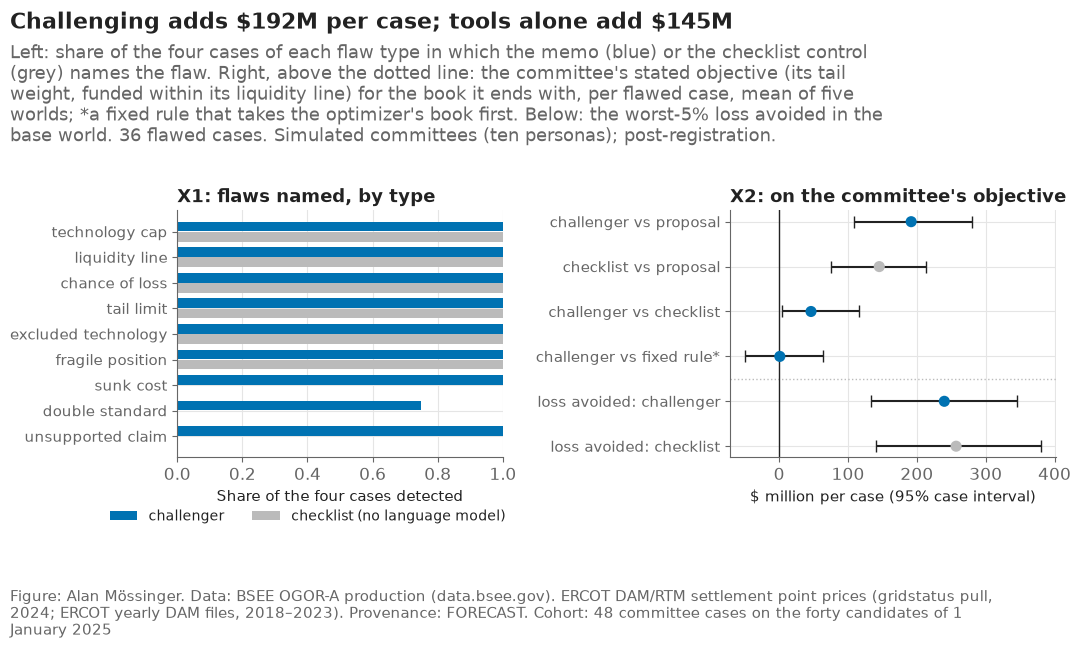

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1]})
order = ["cap", "liquidity", "ploss", "tail", "excluded", "fragile", "sunk", "double", "unsupported"]
names = {"cap": "technology cap", "liquidity": "liquidity line", "ploss": "chance of loss", "tail": "tail limit", "excluded": "excluded technology",
         "fragile": "fragile position", "sunk": "sunk cost", "double": "double standard", "unsupported": "unsupported claim"}
bf = x1_scores[x1_scores["flaw"] != "none"].groupby("flaw")[["challenger_detects", "checklist_detects"]].mean().reindex(order)
y = np.arange(len(order))
axes[0].barh(y - 0.2, bf["challenger_detects"], height=0.38, color="#0072B2", label="challenger")
axes[0].barh(y + 0.2, bf["checklist_detects"], height=0.38, color="#BBBBBB", label="checklist (no language model)")
axes[0].set_yticks(y, [names[f] for f in order], fontsize=10.5)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Share of the four cases detected", fontsize=11)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.4, -0.16), ncol=2, fontsize=10, frameon=False)
axes[0].set_title("X1: flaws named, by type", fontsize=13, loc="left")
labels = ["challenger vs proposal", "checklist vs proposal", "challenger vs checklist", "challenger vs fixed rule*", "loss avoided: challenger", "loss avoided: checklist"]
bs = [cx.case_bootstrap(x2_diffs[c]) for c in ("challenger_minus_proposal", "checklist_minus_proposal", "challenger_minus_checklist")] + [b_of] + \
     [cx.case_bootstrap(x2_diffs[c]) for c in ("loss_avoided_base", "loss_avoided_base_checklist")]
cols = labels
yy = np.arange(len(cols))
axes[1].errorbar([b["mean"] / 1e6 for b in bs], yy, xerr=[[(b["mean"] - b["low"]) / 1e6 for b in bs], [(b["high"] - b["mean"]) / 1e6 for b in bs]],
                 fmt="none", ecolor=plots.INK, capsize=4, lw=1.5)
axes[1].scatter([b["mean"] / 1e6 for b in bs], yy, s=64, zorder=3, color=["#0072B2", "#BBBBBB", "#0072B2", "#0072B2", "#0072B2", "#BBBBBB"], edgecolor=plots.INK)
axes[1].axhline(3.5, color="#BBBBBB", lw=1, ls=":")
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_yticks(yy, labels, fontsize=10.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("$ million per case (95% case interval)", fontsize=11)
axes[1].set_title("X2: on the committee's objective", fontsize=13, loc="left")
c29 = scored9.set_index("id").loc["C29"]
plots.finish(fig, f"Challenging adds \\${c29['estimate'] / 1e6:,.0f}M per case; tools alone add \\${c29['checklist'] / 1e6:,.0f}M",
             "Left: share of the four cases of each flaw type in which the memo (blue) or the checklist control (grey) names the flaw. Right, above the dotted line: the committee's stated objective (its tail weight, funded within its liquidity line) for the book it ends with, per flawed case, mean of five worlds; *a fixed rule that takes the optimizer's book first. Below: the worst-5% loss avoided in the base world. 36 flawed cases. Simulated committees (ten personas); post-registration.",
             "48 committee cases on the forty candidates of 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F46_challenger", "The registered challenger experiments: flaws named by type, and the decision value on the committee's own objective.", NOTEBOOK)
plt.show()

**Reading this.** Left: on the computable flaws the challenger and the checklist are identical; the language model's addition is the bottom three rows, the flaws of argument the checklist cannot see. Right: the committee's book improves by about as much whether it follows the challenger or the checklist (the top two rows overlap), and the challenger's edge over the checklist vanishes against a fixed rule that takes the optimizer's book first. Both avoid a similar amount of worst-5% loss. For a developer, lender or committee this says where the value of the challenge lies: in the computed rules and the alternatives the tools produce, with the language model reading the committee's rules and arguments into them and naming what the numbers cannot. Caveats: simulated committees, one model, 36 cases.

## Takeaways

- Under equal constraints the risk-aware book beats NPV ranking on the registered metric by $320M [+$142M, +$511M], trading $274M of expected value for a worst-5% loss $594M smaller; the ranking holds in all 20 re-selections, the exact book does not (11 of 13 members core). The committee must price that trade.
- The capital plan is the decision's weak point: the construction reserve is exceeded in 44.5% of scenarios, and without a liquidity line book D is worth $1.40B instead of $2.05B. The commitment is the stage-one budget plus a contingent line of up to about $3.3B.
- The machine-learning queue curves do not demonstrably improve the decision: the lookup's book is not distinguishable on the registered metric.
- Revising the book in 2027 with this rule adds nothing; information is worth at most $571M for everything and $52.5M for the ERCOT price level.
- The advisor reads questions into parameters, refuses what it cannot represent and explains only what was computed; its investment increment is zero.
- The active challenger (section 11, registered as decision #96; 6 of 8 lines pass): on 36 flawed committee proposals, following it improves the committee's own objective by $192M per case [+$108M, +$281M] and avoids $240M of worst-5% loss. The checklist with the same tools and no language model does almost as well ($145M; $257M), so most of the value is computed; the language model adds the flaws of argument (11 of 12 named, none by the checklist) and reading rules from words (40 of 40), and over-challenges 2 of 12 clean cases.
- Everything here is post-registration and on what was public on 1 January 2025; the registered record is in `results/registered_v7/`.

**What goes to the report.** Every table of `results/v8/` through `src/report_numbers.py`; figures F38–F42, F44, F45; `results/v9/` and F46 for the challenger.